# SENDAs Update 2010-2024 (Prediction, step 2.7, external case-mix validation of mortality, convenios 3 and 5)


<style type="text/css">
.showopt {
background-color: #004c93; color: #FFFFFF; width: 100px; height: 20px; text-align: center; vertical-align: middle !important; float: right; font-family: sans-serif; border-radius: 8px;
}
.showopt:hover {
background-color: #dfe4f2;
color: #004c93;
}
pre.plot {
background-color: white !important;
}
.tablelines table, .tablelines td, .tablelines th {
border: 1px solid black;
}
.centrado {
text-align: center;
}
.table.center {
margin-left:auto;
margin-right:auto;
}
/* https://vivekjaiskumar.medium.com/css-is-and-not-selector-17c942ec83f :is()*/
/* Applies to outputs that are not code other than R*/
pre {
overflow-x: auto !important;
}
pre code {
word-wrap: normal !important;
white-space: pre !important;
}
/*
pre:not(.sourceCode) {
white-space: nowrap !important;
}
*/
.sourceCode { /* Important gives precedence */
font-size: 10px !important;
line-height: 50% !important;
}
body{ /* Normal */
text-align: justify;
}
.superbigimage{
overflow-y:scroll;
height:350px;
white-space: nowrap;
overflow-x: auto;
width:100%;
}
.superbigimage img{
overflow-y: scroll;
overflow-x: hidden;
}
.message { color:#446C6E; font-family: monospace;font-size: 10px; line-height: 110%; font-weight: bold;}
div.blue { background-color:#e6f0ff; border-radius: 5px; padding: 5px; text-align: justify;}
div.red { background-color:#e6bab1; border-radius: 5px; padding: 5px; text-align: justify;}
.pandoc-table { /* Should add !important; but it seems no necessary */
margin-left:auto; /* To center */
margin-right:auto;
border-collapse: collapse;
table-layout: auto;
font-size: 11px;
overflow-y: auto;
max-height:450px !important;
white-space: nowrap;
overflow-x: auto;
width:450px;
}
.pandoc-table th {/* header */
text-align: center !important;
font-size: 10px;
padding: 0px;
}
.pandoc-table td {
text-align: left !important;
font-size: 9px;
padding: 0px;
}
.pandoc-table caption {
text-align: left !important;
font-size: 11px !important;
}
.center-table {
text-align: left !important;
font-size: 9px;
overflow-y:scroll;
height:450px;
overflow-x: scroll;
}
.controlly{
overflow-y:scroll;
height:350px;
overflow-x: scroll;
}
/*2025-03-07*/
.callout-warning,
.callout-error,
.callout-message {
  font-size: 0.7rem !important;  /* Adjust this value as needed */
}
.alert, .message {
    font-size: 0.7em !important;
}
.alert.alert-warning,
.alert.alert-danger,
.message {
    font-size: 0.7em !important;
}
</style>


<style>
#| label: css-format
h1 {
    color: var(--heading-color);
    font-size: 2rem;
    margin-bottom: 1vh;
}
p {
  font-size: 1.1rem;
  line-height: 1.6rem;
}
a {
  color: var(--primary-color);
  text-decoration: none;
  border-bottom: 3px solid transparent;
  font-weight: bold;
  &:hover, &:focus {
      border-bottom: 3px solid currentColor;
  }
}
section {
  margin: 0 auto;
}
.post-meta {
  font-size: 1rem;
  font-style: italic;
  display: block;
  margin-bottom: 4vh;
  color: var(--secondary-color);
}
nav {
  display: flex;
  justify-content: flex-end;
  padding: 20px 0;
}
/*slider switch css */
.theme-switch-wrapper {
  display: flex;
  align-items: center;
  
  em {
    margin-left: 10px;
    font-size: 1rem;
  }
}
.theme-switch {
  display: inline-block;
  height: 34px;
  position: relative;
  width: 60px;
}
.theme-switch input {
  display:none;
}
.slider {
  background-color: #ccc;
  bottom: 0;
  cursor: pointer;
  left: 0;
  position: absolute;
  right: 0;
  top: 0;
  transition: .4s;
}
.slider:before {
  background-color: #fff;
  bottom: 4px;
  content: "";
  height: 26px;
  left: 4px;
  position: absolute;
  transition: .4s;
  width: 26px;
}
input:checked + .slider {
  background-color: #66bb6a;
}
input:checked + .slider:before {
  transform: translateX(26px);
}
.slider.round {
  border-radius: 34px;
}
.slider.round:before {
  border-radius: 50%;
}
</style>


<style>
.scrollable-content {
  max-height: 350px;
  overflow-y: auto;
}
pre.scrollable-code {
  max-height: 350px;
  overflow-y: auto;
}
.superbigimage {
  overflow-x: scroll;
  white-space: nowrap;
}
.superbigimage img, 
.superbigimage svg {
  max-width: none;
  height: auto;
}
</style>
<br>

# Data Loading and Exploration

## Loading Packages and uniting databases

<div class="scrollable-content">


In [1]:
#| label: setup
#| results: "hold"
#renv falls back to copying rather than symlinking, which is evidently very slow in this configuration.
renv::settings$use.cache(FALSE)
#only use explicit dependencies (in DESCRIPTION)
renv::settings$snapshot.type("implicit")
#check if rstools is installed
if(Sys.info()["sysname"]=="Windows"){
try(installr::install.Rtools(check_r_update=F))
}
check_quarto_version <- function(required = "1.7.29", comparator = c("ge","gt","le","lt","eq")) {
  comparator <- match.arg(comparator)
  current <- package_version(paste(unlist(quarto::quarto_version()), collapse = "."))
  req     <- package_version(required)
  ok <- switch(comparator,
               ge = current >= req,
               gt = current >  req,
               le = current <= req,
               lt = current <  req,
               eq = current == req)
  if (!ok) {
    stop(sprintf("Quarto version check failed: need %s %s (installed: %s).",
                 comparator, required, current), call. = FALSE)
  }
  invisible(TRUE)
}
check_quarto_version("1.7.29", "ge") 
#change repository to CL
local({
  r <- getOption("repos")
  r["CRAN"] <- "https://cran.dcc.uchile.cl/"
  options(repos=r)
})
if(!require(pacman)){install.packages("pacman");require(pacman)}
if(!require(pak)){install.packages("pak");require(pak)}
pacman::p_unlock(lib.loc = .libPaths()) #para no tener problemas reinstalando paquetes
if(Sys.info()["sysname"]=="Windows"){
if (getRversion() != "4.4.1") { stop("Requires R version 4.4.1; Actual: ", getRversion()) }
}
#check docker
check_docker_running <- function() {
  # Try running 'docker info' to check if Docker is running
  system("docker info", intern = TRUE, ignore.stderr = TRUE)
}
if(Sys.info()["sysname"]=="Windows"){
  install_docker <- function() {
    # Open the Docker Desktop download page in the browser for installation
    browseURL("https://www.docker.com/products/docker-desktop")
  }
  # Main logic
  if (inherits(try(check_docker_running(), silent = TRUE), "try-error")) {
    liftr::install_docker()
  } else {
    message("Docker is running.")
  }
}
#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_
#PACKAGES#######################################################################
#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_
unlink("*_cache", recursive=T)
pak::pak_sitrep()
# pak::sysreqs_check_installed(unique(unlist(paks)))
#pak::lockfile_create(unique(unlist(paks)),  "dependencies_duplicates24.lock", dependencies=T)
#pak::lockfile_install("dependencies_duplicates24.lock")
#https://rdrr.io/cran/pak/man/faq.html
#pak::cache_delete()
library(tidytable)
library(ggplot2)
library(readr)
library(tableone)
library(survivalmodels)
#renv::install("patchwork@1.2.0")
library(rms)
library(survidm)
library(caret)
library(survival)
library(riskRegression)
library(prodlim)
library(caret)
library(ggplot2)
library(dplyr)
library(survex)
library(pec)
library(future)
library(future.apply)
library(parallel)
library(mice)
library(riskRegression)
library(tidyr)
library(doFuture)
library(vcd)
library(survAUC)
library(knitr)
if (!requireNamespace("ipeval", quietly = TRUE)) {
  renv::install("ipeval")
}
#flexsurv
#if(!require(compareCstat)){install.pacakges("compareCstat")}
# library(shapr)#https://norskregnesentral.github.io/shapr/
# library(SemiMarkov)#https://www.degruyterbrill.com/document/doi/10.1515/ijb-2020-0083/html?lang=en
# #https://www.jclinepi.com/article/S0895-4356(24)00142-2/fulltext
#_#_#_#_#_#_#_#_#_#_#_#_#_-----------------------------
# 3. Activate polars code completion (safe to try even if it fails)
#_#_#_#_#_#_#_#_#_#_#_#_#_-----------------------------
#try(polars_code_completion_activate())
#_#_#_#_#_#_#_#_#_#_#_#_#_-----------------------------
# 4. BPMN from GitHub (not on CRAN, so install via devtools if missing)
#_#_#_#_#_#_#_#_#_#_#_#_#_-----------------------------
if (!requireNamespace("bpmn", quietly = TRUE)) {
  devtools::install_github("bergant/bpmn")
}
#_#_#_#_#_#_#_#_#_#_#_#_#_-----------------------------
# 5. PhantomJS Check (use webshot if PhantomJS is missing)
#_#_#_#_#_#_#_#_#_#_#_#_#_-----------------------------
# if (!webshot::is_phantomjs_installed()) {
#   webshot::install_phantomjs()
# }
#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_
#FUNCTIONS######################################################################
#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_#_
#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#
# NO MORE DEBUGS
options(error = NULL)        # si antes tenías options(error = recover) o browser)
options(browserNLdisabled = FALSE)
#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#
#NAs are replaced with "" in knitr kable
options(knitr.kable.NA = '')
pander::panderOptions('big.mark', ',')
pander::panderOptions('decimal.mark', '.')

#To produce line breaks in messages and warnings
knitr::knit_hooks$set(
   error = function(x, options) {
     paste('\n\n<div class="alert alert-danger" style="font-size: small !important;">',
           gsub('##', '\n', gsub('^##\ Error', '**Error**', x)),
           '</div>', sep = '\n')
   },
   warning = function(x, options) {
     paste('\n\n<div class="alert alert-warning" style="font-size: small !important;">',
           gsub('##', '\n', gsub('^##\ Warning:', '**Warning**', x)),
           '</div>', sep = '\n')
   },
   message = function(x, options) {
     paste('<div class="message" style="font-size: small !important;">',
           gsub('##', '\n', x),
           '</div>', sep = '\n')
   }
)
tnr<- "Times New Roman" 
options(scipen=2) #display numbers rather scientific number
# ── Helpers ────────────────────────────────────────────────────────────
mode_pick_int <- function(x){
  x <- x[!is.na(x)]
  if(length(x)==0) return(NA_integer_)
  tx <- sort(table(x), decreasing = TRUE)
  as.integer(names(tx)[1L])
}
subkey_to_label <- function(x){
  y <- gsub("_"," ", tolower(x))
  y <- gsub("amphetamine type stimulants","amphetamine-type stimulants", y)
  y <- gsub("tranquilizers hypnotics","tranquilizers/hypnotics", y)
  y
}
#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:
#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:#:
find_latest_file <- function(project_root, prefix) {
  # Get all files matching the pattern
  pattern <- paste0(prefix, "_\\d{8}_\\d{4}\\.csv$")
  files <- list.files(
    path = project_root,
    pattern = pattern,
    full.names = TRUE
  )
  if (length(files) == 0) {
    stop(paste("No files found matching pattern:", pattern))
  }
  # Extract timestamps from filenames (format: YYYYMMDD_HHMM)
  extract_timestamp <- function(filename) {
    matches <- regmatches(
      basename(filename),
      gregexpr("\\d{8}_\\d{4}", basename(filename))
    )
    if (length(matches[[1]]) == 0) {
      return(NA)
    }
    timestamp_str <- matches[[1]][length(matches[[1]])]
    return(timestamp_str)
  }
  timestamps <- sapply(files, extract_timestamp)
  # Remove any files where timestamp extraction failed
  valid_idx <- !is.na(timestamps)
  files <- files[valid_idx]
  timestamps <- timestamps[valid_idx]
  if (length(files) == 0) {
    stop("No valid timestamps found in filenames")
  }
  # Sort by timestamp (descending) and return the latest
  latest_idx <- order(timestamps, decreasing = TRUE)[1]
  return(files[latest_idx])
}

Installing package into ‘C:/Users/andre/AppData/Local/R/win-library/4.4’
(as ‘lib’ is unspecified)


trying URL 'https://cran.rstudio.com/bin/windows/contrib/4.4/pkgbuild_1.4.8.zip'
Content type 'application/zip' length 211084 bytes (206 KB)
downloaded 206 KB



package ‘pkgbuild’ successfully unpacked and MD5 sums checked

The downloaded binary packages are in
	C:\Users\andre\AppData\Local\Temp\RtmpSs3GsF\downloaded_packages
Loading required package: pkgbuild
No need to install Rtools - You've got the relevant version of Rtools installed


Warning message:
package ‘pkgbuild’ was built under R version 4.4.3 


Loading required package: pacman


...

Warning message:
package ‘pec’ was built under R version 4.4.3 



Attaching package: ‘future’

The following object is masked from ‘package:survival’:

    cluster

The following object is masked from ‘package:caret’:

    cluster



Warning message:
package ‘future.apply’ was built under R version 4.4.3 


Registered S3 method overwritten by 'broom':
  method        from          
  nobs.multinom riskRegression

Attaching package: ‘mice’

The following objects are masked from ‘package:tidytable’:

    complete, filter

The following object is masked from ‘package:stats’:

    filter

The following objects are masked from ‘package:base’:

    cbind, rbind


Attaching package: ‘tidyr’

The following objects are masked from ‘package:tidytable’:

    complete, crossing, drop_na, expand, expand_grid, extract, fill, nest, nesting, pivot_longer, pivot_wider, replace_na, separate,
    separate_longer_delim, separate_rows, separate_wider_delim, separate_wider_regex, tribble, uncount, unite, unnest, unnest_longer,
    unnest_wider

Loading required package: foreach
Loading required package: grid


Warning message:
package ‘survAUC’ was built under R version 4.4.3 
Warning message:
package ‘knitr’ was built under R version 4.4.3 


In [2]:
#| label: define-project-root-and-paths
root <- here::here()
project_root <- gsub("/cons$", "", root)
data_out <- file.path(project_root, "data", "20241015_out")
figs_out <- file.path(root, "_figs")
out_dir  <- file.path(project_root, "cons", "_out")

In [3]:
#| label: set-global-options
#| message: false

options(future.globals.maxSize = 10 * 1024^3)

# External (case-mix) validation: post-discharge mortality on SENDA convenios 3 and 5

The mortality model (best_perf2, the SHAP-reduced cause-specific Cox of time from discharge to all-cause death) was developed on convenio 1 (general population, plus women's plans), adults 18-64, admitted 2010-2020. Here it is applied **without refitting** to two independent SENDA agreements the model never saw:

- **Convenio 3** -- population experiencing homelessness (adults).

The model is fit on the full development cohort (5 MICE imputations) and predictions are pooled across imputations (mean linear predictor for ranking, mean survival for IBS and calibration). Patients already in the development cohort are excluded, so there is no overlap. The DEIS mortality registry covers deaths through 2020, so this is a same-era case-mix validation (not temporal) and follow-up is censored at 2020-12-31, the same death-ascertainment window the model was developed on.

Raw C3 variables are recoded to the development schema and labels. The plan-type stratum is mapped to the nearest development modality (C3 to pg-pr); Uno's C-index does not depend on the baseline hazard, so it transports regardless, while IBS and calibration borrow the development baseline of the mapped stratum.

In [4]:
#| label: extval-config
#| message: false
# Fixed analysis constants. There is deliberately NO run-mode switch here: pred26's
# configuration cell reads Sys.getenv("PRED26_RUN_MODE", "smoke") and only escapes the
# smoke default because its setup cell sets the variable to "full" beforehand. That is
# fragile, so this notebook hardcodes production values and asserts them instead.
project_root <- gsub("/cons$", "", getwd())
source(file.path(project_root, "cons/_alt_scripts/extval_death_01_build_cohort.R"))
source(file.path(project_root, "cons/_alt_scripts/run_extval_death.R"))
source(file.path(project_root, "cons/_alt_scripts/extval_death_02_table1_smd.R"))
source(file.path(project_root, "cons/_alt_scripts/extval_death_03_ibs_grid_cc.R"))
# Evaluation grid. IDENTICAL to prediction23_converted_mod's EVAL_TIMES so the IBS values
# are comparable: ibs_ipcw_train() integrates the Brier curve over exactly these points and
# normalises by max - min, so any change to this vector changes the estimand (eval_times trap).
# The DEIS mortality registry covers 2008-2020, so follow-up is censored 2020-12-31; C3 and C5
# are discharged on or before that date with follow-up up to about 79 months, which is why the
# 60-month horizon IS supported here, unlike the readmission temporal cohort.
EVAL_TIMES <- c(3, 6, 12, 36, 60)
CAL_TIMES  <- c(6, 12, 36, 60)
B_BOOT     <- 1000L
SEED       <- 2125L
# Frozen model metadata, asserted in the next cell.
MODEL_COEFFICIENT_PARAMETERS <- 14L
MODEL_STRATA_TERMS           <- 2L
# Guard: fail loudly if anyone reintroduces a reduced-effort run through the environment.
if (nzchar(Sys.getenv("PRED27_RUN_MODE", ""))) {
  stop("PRED27_RUN_MODE is set. This notebook has no reduced run mode; unset it.", call. = FALSE)
}
if (B_BOOT < 1000L) stop("B_BOOT must be 1000 for a reportable run.", call. = FALSE)
stopifnot(identical(EVAL_TIMES, c(3, 6, 12, 36, 60)))
# knitr::kable returned as a cell value is not auto-displayed by the Jupyter/Quarto jupyter
# engine (knitr_kable has no display method). Emit it as markdown so it renders as a real
# table; fall back to print() if IRdisplay is unavailable.
show_kable <- function(k) {
  if (requireNamespace("IRdisplay", quietly = TRUE))
    IRdisplay::display_markdown(paste(as.character(k), collapse = "\n"))
  else print(k)
}
# Same idea for an htmltools/browsable object (the SMD table).
show_html <- function(x) {
  if (requireNamespace("IRdisplay", quietly = TRUE))
    IRdisplay::display_html(as.character(htmltools::as.tags(x)))
  else print(x)
}
config <- data.frame(
  item = c("eval_times", "cal_times", "bootstrap_replicates", "seed",
           "coefficient_parameters", "strata_terms", "external_cohort_handling",
           "development_cohort_handling", "ibs_engine", "project_root"),
  value = c(paste(EVAL_TIMES, collapse = ", "), paste(CAL_TIMES, collapse = ", "),
            B_BOOT, SEED, MODEL_COEFFICIENT_PARAMETERS, MODEL_STRATA_TERMS,
            "complete case on model predictors and outcome",
            "5 MICE imputations, Rubin-pooled (matches prediction23 best_perf2)",
            "ibs_ipcw_train(), same grid and normalisation as prediction23",
            project_root))
show_kable(knitr::kable(config, "markdown", caption = "Pre-specified run configuration"))



Table: Pre-specified run configuration

|item                        |value                                                              |
|:---------------------------|:------------------------------------------------------------------|
|eval_times                  |3, 6, 12, 36, 60                                                   |
|cal_times                   |6, 12, 36, 60                                                      |
|bootstrap_replicates        |1000                                                               |
|seed                        |2125                                                               |
|coefficient_parameters      |14                                                                 |
|strata_terms                |2                                                                  |
|external_cohort_handling    |complete case on model predictors and outcome                      |
|development_cohort_handling |5 MICE imputations, Rubin-pooled (mat

Any saved result before July 20th used `formula_shap_death` and now we are using `*_rule2`. 

In [5]:
#| label: extval-frozen-formula-contract
# The frozen mortality model is best_perf2 = formula_shap_death_rule2, taken verbatim from
# prediction23_converted_mod. It is written out here rather than left inside
# load_death_formula() so the specification is auditable from the rendered document.
# NOTE ON PROVENANCE: run_extval_death.R switched from the retired 13-variable
# formula_shap_death to rule2 on 2026-07-20. Any saved result predating that date, including
# data/20241015_out/pred27/extval_death_2026_07_04.rds, was produced by the RETIRED model and
# must not be cited. The retired cohort did not even build the cohabitation column.
f_death <- load_death_formula()
print(f_death)
DEATH_COEFFICIENT_COLUMNS <- c(
  "adm_age_rec3",
  "primary_sub_mod_cocaine_paste", "primary_sub_mod_cocaine_powder",
  "primary_sub_mod_alcohol", "primary_sub_mod_others",
  "prim_sub_freq_rec_2_2_6_days_wk", "prim_sub_freq_rec_3_daily",
  "occupation_condition_corr24_unemployed", "occupation_condition_corr24_inactive",
  "eva_ocupacion_logro_intermedio", "eva_ocupacion_logro_minimo",
  "cohabitation_family_of_origin", "cohabitation_with_couple_children",
  "cohabitation_others")
DEATH_STRATA_COLUMNS <- c("plan_type_strata", "any_phys_dx")
DEATH_OUTCOME_COLUMNS <- c("death_time_from_disch_m", "death_event")
stopifnot(length(DEATH_COEFFICIENT_COLUMNS) == MODEL_COEFFICIENT_PARAMETERS)
stopifnot(length(DEATH_STRATA_COLUMNS) == MODEL_STRATA_TERMS)
# Verify the declared contract against the formula actually returned, so the two cannot drift.
.f_terms <- attr(stats::terms(f_death), "term.labels")
.f_strata <- sub("^strata\\((.*)\\)$", "\\1", grep("^strata\\(", .f_terms, value = TRUE))
.f_coefs  <- setdiff(.f_terms, grep("^strata\\(", .f_terms, value = TRUE))
stopifnot(setequal(.f_coefs, DEATH_COEFFICIENT_COLUMNS))
stopifnot(setequal(.f_strata, DEATH_STRATA_COLUMNS))
cat("Frozen model contract verified:", length(.f_coefs), "coefficients,",
    length(.f_strata), "strata terms.\n")

Surv(death_time_from_disch_m, death_event) ~ adm_age_rec3 + primary_sub_mod_cocaine_paste + 
    primary_sub_mod_cocaine_powder + primary_sub_mod_alcohol + 
    primary_sub_mod_others + prim_sub_freq_rec_2_2_6_days_wk + 
    prim_sub_freq_rec_3_daily + occupation_condition_corr24_unemployed + 
    occupation_condition_corr24_inactive + eva_ocupacion_logro_intermedio + 
    eva_ocupacion_logro_minimo + cohabitation_family_of_origin + 
    cohabitation_with_couple_children + cohabitation_others + 
    strata(plan_type_strata) + strata(any_phys_dx)
Frozen model contract verified: 14 coefficients, 2 strata terms.


### Excluding deaths before discharge and after discharge if administrative artifact is suspected

In [6]:
#| label: extval-alive-at-origin-contract
# Cohort definition contract. The frozen model is evaluated on a cohort that is ALIVE at the time
# origin, which is the discharge date. Two rules enforce that, and both are stated here rather than
# left implicit inside the builder, so the definition is auditable from the rendered document.
# RULE A. Patients whose registered death date falls at or before the discharge date are removed.
# The old code kept them: death_event required def_date >= .disch, so a patient who died BEFORE
# discharge failed that test and was carried as a censored survivor, that is, a dead patient counted
# as alive. Convenio 3 had 20 such patients against 82 deaths, plus 8 deaths dated exactly on the
# discharge day, which enter as a degenerate zero-time prediction target.
# RULE B. Deaths occurring within PRECAUTION_MONTHS of an ADMINISTRATIVE discharge are removed. An
# administrative discharge immediately followed by death is plausibly a consequence of the terminal
# event rather than a prognosis issued from a stable state. The restriction to administrative
# discharges is deliberate: applied to every discharge reason the window would also remove deaths
# after therapeutic discharge and dropout, which are ordinary post-discharge deaths and belong in
# the outcome.
# SCOPE. Both rules apply ONLY to the external validation cohorts. Development and the held-out test
# set are untouched, so this is a validation-side definition, and the mismatch with development must
# be declared in the manuscript.
COHORT_ALIVE_AT_DISCHARGE <- TRUE
PRECAUTION_MONTHS <- 0.23
PRECAUTION_SCOPE <- "administrative"
EXTVAL_COHORT_OPTS <- list(alive_at_discharge = COHORT_ALIVE_AT_DISCHARGE,
                           precaution_months = PRECAUTION_MONTHS,
                           precaution_scope = PRECAUTION_SCOPE)
# Guard: the builder must actually support these arguments. If an older copy of the engine is on the
# path this fails here rather than silently ignoring the settings and producing the historical
# cohort under a label that claims otherwise.
.bf <- names(formals(build_extval_death_cohort))
stopifnot(all(c("alive_at_discharge", "precaution_months", "precaution_scope") %in% .bf))
stopifnot("cohort_opts" %in% names(formals(run_extval_death)))
cat("Cohort definition: alive at discharge =", COHORT_ALIVE_AT_DISCHARGE,
    "| precautionary window =", PRECAUTION_MONTHS, "months | scope =", PRECAUTION_SCOPE, "\n")
# Build both cohorts once, cheaply, only to display the flow. run_extval_death() rebuilds them
# internally with the same options, so this is a report and not the analysis cohort.
alive_flow <- lapply(c("C3", "C5"), function(w) {
  b <- do.call(build_extval_death_cohort, c(list(which = w, verbose = FALSE), EXTVAL_COHORT_OPTS))
  h <- do.call(build_extval_death_cohort,
               c(list(which = w, verbose = FALSE),
                 list(alive_at_discharge = FALSE, precaution_scope = "none")))
  cc <- function(d) stats::complete.cases(d[, EVD_NEED_COMPLETE, drop = FALSE])
  ib <- cc(b$nondum); ih <- cc(h$nondum)
  list(convenio = w, flow = b$flow, params = b$params,
       summary = data.frame(
         arm = c("historical code (adversarial arm)", "alive at origin (PRIMARY)"),
         raw_n = c(nrow(h$nondum), nrow(b$nondum)),
         raw_deaths = c(sum(h$nondum$death_event == 1L), sum(b$nondum$death_event == 1L)),
         complete_case_n = c(sum(ih), sum(ib)),
         complete_case_deaths = c(sum(h$nondum$death_event[ih] == 1L), sum(b$nondum$death_event[ib] == 1L)),
         stringsAsFactors = FALSE))
})
names(alive_flow) <- c("C3", "C5")
for (w in names(alive_flow)) {
  show_kable(knitr::kable(alive_flow[[w]]$flow, "markdown", digits = 0, row.names = FALSE,
    caption = paste0("Convenio ", w, ". Cohort flow under the post-discharge definition. The two removal rows are the alive-at-origin rule and the precautionary window; every other row is unchanged from the historical build.")))
  show_kable(knitr::kable(alive_flow[[w]]$summary, "markdown", digits = 0, row.names = FALSE,
    caption = paste0("Convenio ", w, ". What each definition leaves, raw and after the complete-case restriction on the model predictors and the outcome. The adversarial arm is reported so the cost of the decision is visible, not to be used as the primary result.")))
}
# Composition of the discharge reason among the patients the rules removed, so the exclusion is
# justified by what the registry says and not only by date arithmetic.
reason_mix <- do.call(rbind, lapply(c("C3", "C5"), function(w) {
  h <- do.call(build_extval_death_cohort,
               c(list(which = w, verbose = FALSE),
                 list(alive_at_discharge = FALSE, precaution_scope = "none")))$nondum
  na <- !is.na(h$def_date) & !is.na(h$.disch) & h$def_date <= h$.disch
  if (!any(na)) return(NULL)
  z <- as.data.frame(table(dplyr::coalesce(h$disch_reason[na], "(missing)")), stringsAsFactors = FALSE)
  names(z) <- c("disch_reason", "n"); z$convenio <- w; z[, c("convenio", "disch_reason", "n")]
}))
show_kable(knitr::kable(reason_mix, "markdown", digits = 0, row.names = FALSE,
  caption = "Discharge reason among the patients removed for not being alive at the time origin. The registry itself codes most of them as an administrative discharge, which corroborates the date-based exclusion."))
flush.console()

Cohort definition: alive at discharge = TRUE | precautionary window = 0.23 months | scope = administrative 


Table: Convenio C3. Cohort flow under the post-discharge definition. The two removal rows are the alive-at-origin rule and the precautionary window; every other row is unchanged from the historical build.

|step                                                            |    n|
|:---------------------------------------------------------------|----:|
|raw rows                                                        | 3077|
|raw patients                                                    | 2155|
|after excluding development patients                            | 1990|
|adults 18-64                                                    | 1807|
|with discharge <= 2020-12-31                                    |  720|
|first episode per patient                                       |  648|
|removed: not alive at the discharge origin                      |   28|
|removed: death within 0.23

## Frozen mortality model, development fit, cohorts and bootstrap

`run_extval_death()` builds the development fit (cached), recodes and dummifies the C3 and C5 cohorts, applies the frozen model, computes discrimination, IBS and calibration with bootstrap 95% CIs, derives the common-support matched subsamples, and assembles the development-vs-external SMD table. The full result object is saved to `data/20241015_out/pred27/`.

In [7]:
#| label: extval-run
#| message: false
# Parallel backend for the bootstrap (sequential worker startup avoids the
# 'workers failed to connect' timeout on Drive paths).
if (requireNamespace("future", quietly = TRUE) && !inherits(future::plan(), "multisession")) {
  options(parallelly.makeNodePSOCK.setup_strategy = "sequential")
  options(parallelly.makeNodePSOCK.connectTimeout = 600)
  future::plan(future::multisession, workers = min(8L, max(1L, parallelly::availableCores() %/% 2L)))
}
options(future.globals.maxSize = 10 * 1024^3)

res <- run_extval_death(eval_times = EVAL_TIMES, cal_times = CAL_TIMES,
                        B = B_BOOT, seed = 2125L, parallel = TRUE, save = TRUE, verbose = TRUE,
                        cohort_opts = EXTVAL_COHORT_OPTS)
cat(sprintf("Convenio 3: n=%d, deaths=%d (%.1f%%); matched n=%d.\n",
            res$C3$n, res$C3$n_events, 100*res$C3$n_events/res$C3$n, res$C3$match$n))

Loading cached dev (full) dummified: g:/My Drive/Alvacast/SISTRAT 2023/data/20241015_out/_val_inputs/extval_dev_full_dummified.rds 
Fitted mortality model on 5 dev imputations.

================= C3 =================
[C3] raw: rows=3,077 patients=2,155
1. exclude development-cohort patients: removed 1,087 rows; 1,990 remain
2. adults 18-64: 1,807 ; with discharge on/before 2020-12-31: 720
3. first episode per patient: 648
5. post-discharge definition (alive_at_discharge=TRUE, precaution=administrative 0.23 m):
   not alive at the discharge origin: 28 (of which 20 were carried as censored survivors, 8 as zero-time deaths)
   deaths inside the precautionary window: 5 total, 2 after an administrative discharge, 2 removed under the chosen scope
   removed in total: 30 ; remaining: 618

=== C3 DEATH COHORT FLOW ===
                                                            step    n
                                                        raw rows 3077
                                      

## Structuring the cohort

In [8]:
#| label: extval-flow-c3
show_kable(knitr::kable(res$C3$flow, "markdown",
  caption = "Convenio 3 (population experiencing homelessness): mortality cohort construction (alive at the discharge origin; deaths censored 2020-12-31)"))



Table: Convenio 3 (population experiencing homelessness): mortality cohort construction (alive at the discharge origin; deaths censored 2020-12-31)

|step                                                            |    n|
|:---------------------------------------------------------------|----:|
|raw rows                                                        | 3077|
|raw patients                                                    | 2155|
|after excluding development patients                            | 1990|
|adults 18-64                                                    | 1807|
|with discharge <= 2020-12-31                                    |  720|
|first episode per patient                                       |  648|
|removed: not alive at the discharge origin                      |   28|
|removed: death within 0.23 months of a administrative discharge |    2|
|alive-at-origin cohort (FINAL)                                  |  618|
|deaths (post-discharge, <= censor)           

In [9]:
#| label: explore-c3-flow

# Guard against reloading a pre-patch result. The builder gained two exclusion rows on 2026-07-28,
# so a flow table with 8 rows was written before the patch and its cohort is the retired one.
stopifnot(nrow(res$C3$flow) == 11L)

project_root <- "g:/My Drive/Alvacast/SISTRAT 2023"

# List available saved results
rds_files <- list.files(file.path(project_root, "data/20241015_out/pred27"),
                        pattern = "^extval_death_.*\\.rds$", full.names = TRUE)
cat("Available RDS files:\n")
print(rds_files)

# Pick the most recent one
rds_file <- tail(sort(rds_files), 1)
cat("\nLoading:", rds_file, "\n")

res <- readRDS(rds_file)

# Cohort construction flow for C3
cat("\n=== C3 cohort flow ===\n")
print(res$C3$flow, row.names = FALSE)

# Sizes of the analysed subsets
cat("\n=== C3 sample sizes ===\n")
cat("Full (complete-case) n:", nrow(res$C3$nondum_cc), "\n")
cat("Common-support keep:", sum(res$C3$match$info$keep), "/", length(res$C3$match$info$keep), "\n")
cat("1:1 NN keep:", sum(res$C3$nn$info$keep), "/", length(res$C3$nn$info$keep), "\n")

Available RDS files:
[1] "g:/My Drive/Alvacast/SISTRAT 2023/data/20241015_out/pred27/extval_death_2026_06_29.rds"
[2] "g:/My Drive/Alvacast/SISTRAT 2023/data/20241015_out/pred27/extval_death_2026_07_04.rds"
[3] "g:/My Drive/Alvacast/SISTRAT 2023/data/20241015_out/pred27/extval_death_2026_07_28.rds"

Loading: g:/My Drive/Alvacast/SISTRAT 2023/data/20241015_out/pred27/extval_death_2026_07_28.rds 

=== C3 cohort flow ===
                                                            step    n
                                                        raw rows 3077
                                                    raw patients 2155
                            after excluding development patients 1990
                                                    adults 18-64 1807
                                    with discharge <= 2020-12-31  720
                                       first episode per patient  648
                      removed: not alive at the discharge origin   28
 removed: death wi

  - **first episode per patient**= retains only the first eligible episode per patient, using discharge as the time-zero anchor. This is an intermediate count, not the analyzed cohort.
  
  - **alive-at-origin cohort (FINAL)**= after excluding those who were not alive at the start of follow-up and deaths within 0.23 months of an administrative discharge. This is the analyzed n: 618 in C3.

In [10]:
#| label: explore-c3-raw-vs-analyzed
# Source the cohort builder and reconstruct the raw C3 data
setwd(file.path(project_root, "cons"))
source(file.path(project_root, "cons/_alt_scripts/extval_death_01_build_cohort.R"))

built_c3 <- build_extval_death_cohort("C3", verbose = FALSE)

# Defensive extraction: built_c3$nondum should be the data.frame
nondum_raw <- if (is.data.frame(built_c3$nondum)) built_c3$nondum else built_c3$nondum$nondum

cat("=== Raw vs analysed C3 ===\n")
cat("Raw rows:", nrow(nondum_raw), "\n")
cat("Analysed rows (nondum_cc):", nrow(res$C3$nondum_cc), "\n")
cat("Dropped by complete-case / dummification:", nrow(nondum_raw) - nrow(res$C3$nondum_cc), "\n")

# Flag who made it into the analysed sample
nondum_raw$in_analysis <- nondum_raw$hash_key %in% res$C3$nondum_cc$hash_key

cat("\n=== Included in final analysis ===\n")
print(table(in_analysis = nondum_raw$in_analysis, useNA = "ifany"))

# Look at dropped patients
dropped <- nondum_raw[!nondum_raw$in_analysis, ]
if (nrow(dropped) > 0) {
  cat("\n=== Dropped patients ===\n")
  print(dropped[, intersect(names(dropped),
                            c("adm_age_rec3", "sex_rec", "primary_sub_mod",
                              "prim_sub_freq_rec", "occupation_condition_corr24",
                              "plan_type_corr", "death_event"))])
}

=== Raw vs analysed C3 ===
Raw rows: 618 
Analysed rows (nondum_cc): 605 
Dropped by complete-case / dummification: 13 

=== Included in final analysis ===
in_analysis
FALSE  TRUE 
   13   605 

=== Dropped patients ===
    adm_age_rec3 sex_rec primary_sub_mod prim_sub_freq_rec occupation_condition_corr24 plan_type_corr death_event
89            50     man   cocaine paste              <NA>                    inactive          pg-pr           0
92            55     man         alcohol              <NA>                    employed          pg-pr           0
180           48     man   cocaine paste           3.Daily                  unemployed          pg-pr           0
202           36     man   cocaine paste           3.Daily                    inactive          pg-pr           0
276           47     man   cocaine paste       1.≤1 day/wk                  unemployed          pg-pr           0
327           50   woman   cocaine paste              <NA>                    inactive          

In [11]:
#| label: extval-complete-case-diagnostics
# Complete-case reporting for the external cohorts. The complete-case FILTER itself is already
# in force: run_extval_death() calls dummify_extval_death(..., complete_case = TRUE). What was
# missing was the evidence that the dropped rows do not differ systematically from the retained
# ones, which is the diagnostic prediction26_ext_val_readm_mod reports as smd_complete_vs_dropped.
# Note the deliberate asymmetry, which belongs in the estimands section: the DEVELOPMENT side
# keeps the 5 MICE imputations because the frozen model must remain identical to prediction23's
# best_perf2, while the EXTERNAL side is complete case.
cc_report <- function(which_convenio) {
  built <- build_extval_death_cohort(which_convenio, verbose = FALSE)
  dat   <- dummify_extval_death(built$nondum, complete_case = TRUE, verbose = FALSE)
  idx   <- attr(dat, "cc_index")
  miss  <- evd_missingness_report(built$nondum)
  flow  <- evd_complete_case_flow(built$flow, nrow(built$nondum), nrow(dat),
                                  sum(dat$death_event == 1L, na.rm = TRUE))
  smd   <- evd_smd_complete_vs_dropped(built$nondum, idx)
  list(convenio = which_convenio, missing = miss, flow = flow, smd = smd,
       n_before = nrow(built$nondum), n_after = nrow(dat))
}
cc_c3 <- cc_report("C3")
show_kable(knitr::kable(cc_c3$flow, "markdown",
  caption = "Convenio 3: cohort flow, now ending at the complete-case analysis sample."))
show_kable(knitr::kable(cc_c3$missing[cc_c3$missing$missing > 0, ], "markdown", row.names = FALSE,
  caption = "Convenio 3: missing values on model predictors and outcome, before the complete-case filter."))
show_kable(knitr::kable(head(cc_c3$smd, 12), "markdown", row.names = FALSE, digits = 3,
  caption = paste0("Convenio 3: standardized mean differences between the ", cc_c3$n_after,
    " retained complete cases and the ", cc_c3$n_before - cc_c3$n_after,
    " rows dropped for missingness. Positive means the dropped rows sit above the retained ones.",
    " Interpret with caution: the dropped group is small, so these estimates are unstable.")))
cat(sprintf("Convenio 3 complete case: %d of %d rows retained (%.1f%% dropped).\n",
            cc_c3$n_after, cc_c3$n_before,
            100 * (cc_c3$n_before - cc_c3$n_after) / cc_c3$n_before))



Table: Convenio 3: cohort flow, now ending at the complete-case analysis sample.

|step                                                            |    n|
|:---------------------------------------------------------------|----:|
|raw rows                                                        | 3077|
|raw patients                                                    | 2155|
|after excluding development patients                            | 1990|
|adults 18-64                                                    | 1807|
|with discharge <= 2020-12-31                                    |  720|
|first episode per patient                                       |  648|
|removed: not alive at the discharge origin                      |   28|
|removed: death within 0.23 months of a administrative discharge |    2|
|alive-at-origin cohort (FINAL)                                  |  618|
|deaths (post-discharge, <= censor)                              |   72|
|censored                               

In [12]:
#| label: extval-structural-zeros
# Structural zeros in the external cohorts. A coefficient dummy with no variation in the external
# set contributes only a constant to the linear predictor there. This does not bias the frozen
# model (it is not refitted) but it must be declared, because it means that term carries no
# information in this validation.
# VERIFIED for convenio 3: the source column con_quien_vive exists and is COMPLETE (0 missing),
# with levels solo/a (2112), con amigos (424), unicamente con pareja (310), otros (203),
# unicamente con la pareja e hijos/as (16), unicamente con hijos/as (12).
# The recoding is NOT at fault: no raw C3 value contains padre, madre, abuelo, hermano, familia
# de origen or pariente, so nothing is being misrouted by .evd_cohabitation().
# But this is an INSTRUMENT difference, not a clean population fact, and it must be reported as
# such. The C3 form offers only those six options and has no family-of-origin option at all,
# whereas the C1 development form does and 37.0% of the development cohort (32,597 of 88,152)
# selects it. Any C3 patient living with parents was therefore forced into "otros" or
# "con amigos". The zero conflates a real feature of a population experiencing homelessness with
# the inability of the C3 instrument to record that category, and the two cannot be separated
# with these data. Treat it as a transportability limitation of the cohabitation block.
structural_zero_report <- function(dat, terms = DEATH_COEFFICIENT_COLUMNS, label = "") {
  present <- intersect(terms, names(dat))
  out <- data.frame(
    term = present,
    n_nonzero = vapply(dat[present], function(v) sum(as.numeric(v) != 0, na.rm = TRUE), integer(1)),
    stringsAsFactors = FALSE)
  out$prevalence <- round(out$n_nonzero / nrow(dat), 4)
  out$status <- ifelse(out$n_nonzero == 0L, "STRUCTURAL ZERO",
                ifelse(out$prevalence < 0.01, "very rare (<1%)", ""))
  out$cohort <- label
  out[order(out$n_nonzero), ]
}
# run_extval_death() returns the pre-dummy cohort in $nondum_cc but not the dummified model
# matrix, so the frame is rebuilt here. This is cheap: the builder reads a small cached extract.
built_c3 <- build_extval_death_cohort("C3", verbose = FALSE)
dat_c3   <- dummify_extval_death(built_c3$nondum, complete_case = TRUE, verbose = FALSE)
sz_c3    <- structural_zero_report(dat_c3, label = "Convenio 3")
show_kable(knitr::kable(sz_c3, "markdown", row.names = FALSE,
  caption = "Coefficient-term prevalence in the external cohort. Terms flagged STRUCTURAL ZERO carry no information in this validation."))
cat("Levels of the source cohabitation variable in convenio 3, for the record:\n")
print(table(built_c3$nondum$cohabitation, useNA = "ifany"))



Table: Coefficient-term prevalence in the external cohort. Terms flagged STRUCTURAL ZERO carry no information in this validation.

|term                                   | n_nonzero| prevalence|status          |cohort     |
|:--------------------------------------|---------:|----------:|:---------------|:----------|
|cohabitation_family_of_origin          |         0|     0.0000|STRUCTURAL ZERO |Convenio 3 |
|primary_sub_mod_others                 |         7|     0.0116|                |Convenio 3 |
|primary_sub_mod_cocaine_powder         |        19|     0.0314|                |Convenio 3 |
|cohabitation_with_couple_children      |        70|     0.1157|                |Convenio 3 |
|cohabitation_others                    |       123|     0.2033|                |Convenio 3 |
|prim_sub_freq_rec_2_2_6_days_wk        |       171|     0.2826|                |Convenio 3 |
|occupation_condition_corr24_inactive   |       176|     0.2909|                |Convenio 3 |
|eva_ocupacion_logro_

In [13]:
#| label: explore-c3-recoding
# Source the full pipeline to access dummify_extval_death() and the model formula
source(file.path(project_root, "cons/_alt_scripts/run_extval_death.R"))

cat("=== Mortality model formula ===\n")
print(load_death_formula())

cat("\n=== Covariates used in propensity matching ===\n")
print(.EVD_DEATH_TERMS)

# Rebuild the dummified analysis data.frame from the raw complete-case cohort
dat <- dummify_extval_death(nondum_raw, complete_case = TRUE, verbose = TRUE)

cat("\n=== Dummified columns ===\n")
print(names(dat))

cat("\n=== First rows of dummified data ===\n")
print(head(dat[, 1:min(15, ncol(dat))]))

# Compare recoded variables with their original values
cat("\n=== Mapping: age group recoding ===\n")
print(dplyr::distinct(nondum_raw, adm_age_rec3) %>% dplyr::arrange(adm_age_rec3))

cat("\n=== Mapping: primary substance recoding ===\n")
print(dplyr::distinct(nondum_raw, primary_sub_mod) %>% dplyr::arrange(primary_sub_mod))

cat("\n=== Mapping: frequency recoding ===\n")
print(dplyr::distinct(nondum_raw, prim_sub_freq_rec) %>% dplyr::arrange(prim_sub_freq_rec))

=== Mortality model formula ===
Surv(death_time_from_disch_m, death_event) ~ adm_age_rec3 + primary_sub_mod_cocaine_paste + 
    primary_sub_mod_cocaine_powder + primary_sub_mod_alcohol + 
    primary_sub_mod_others + prim_sub_freq_rec_2_2_6_days_wk + 
    prim_sub_freq_rec_3_daily + occupation_condition_corr24_unemployed + 
    occupation_condition_corr24_inactive + eva_ocupacion_logro_intermedio + 
    eva_ocupacion_logro_minimo + cohabitation_family_of_origin + 
    cohabitation_with_couple_children + cohabitation_others + 
    strata(plan_type_strata) + strata(any_phys_dx)

=== Covariates used in propensity matching ===
 [1] "adm_age_rec3"                           "primary_sub_mod_cocaine_paste"          "primary_sub_mod_cocaine_powder"        
 [4] "primary_sub_mod_alcohol"                "primary_sub_mod_others"                 "prim_sub_freq_rec_2_2_6_days_wk"       
 [7] "prim_sub_freq_rec_3_daily"              "occupation_condition_corr24_unemployed" "occupation_condition_cor

In [14]:
#| label: find-lost-deaths

# Guard against reloading a pre-patch result. The builder gained two exclusion rows on 2026-07-28,
# so a flow table with 8 rows was written before the patch and its cohort is the retired one.
stopifnot(nrow(res$C3$flow) == 11L)

project_root <- "g:/My Drive/Alvacast/SISTRAT 2023"
setwd(file.path(project_root, "cons"))

res <- readRDS(tail(sort(list.files(
  file.path(project_root, "data/20241015_out/pred27"),
  pattern = "^extval_death_.*\\.rds$", full.names = TRUE)), 1))

source(file.path(project_root, "cons/_alt_scripts/extval_death_01_build_cohort.R"))
built_c3 <- build_extval_death_cohort("C3", verbose = FALSE)
nondum_raw <- if (is.data.frame(built_c3$nondum)) built_c3$nondum else built_c3$nondum$nondum

# Final cohort before complete-case dropping
final_cohort <- nondum_raw
cat("Final cohort before CC: n =", nrow(final_cohort), ", deaths =", sum(final_cohort$death_event, na.rm = TRUE), "\n")

# Variables required for complete-case analysis
stopifnot(exists("EVD_NEED_COMPLETE"))
need_vars <- EVD_NEED_COMPLETE

# Patients with any missing required variable
missing_any <- !stats::complete.cases(final_cohort[, need_vars, drop = FALSE])
lost <- final_cohort[missing_any, ]

cat("Patients dropped by complete-case rules:", nrow(lost), "\n")
cat("Deaths among dropped patients:", sum(lost$death_event == 1L, na.rm = TRUE), "\n")

cat("\n=== Dropped patients ===\n")
print(lost[, c("hash_key", "death_event", "death_time_from_disch_m",
               intersect(need_vars, names(lost))) ])

cat("\n=== Missing pattern per variable ===\n")
missing_pattern <- sapply(need_vars, function(v) sum(is.na(lost[[v]])))
print(missing_pattern[missing_pattern > 0])

# Cross-check against the engine itself. If these disagree, the cell is lying about the analysis.
.dat_check <- dummify_extval_death(final_cohort, complete_case = TRUE, verbose = FALSE)
stopifnot(nrow(final_cohort) - nrow(.dat_check) == nrow(lost))
cat("Cross-check against dummify_extval_death(): dropped", nrow(lost), "rows, agreed.\n")

Final cohort before CC: n = 618 , deaths = 72 
Patients dropped by complete-case rules: 13 
Deaths among dropped patients: 1 

=== Dropped patients ===
                                                            hash_key death_event death_time_from_disch_m primary_sub_mod prim_sub_freq_rec
89  273a41ba5b2a048a265f0fdb5df64d65ea8b19036e9565abbdf19ffc097d8008           0                12.35484   cocaine paste              <NA>
92  289dffe700f06b4f40267aab5fbfbf39e37f0487f2cf04a537ba2edef48f8f75           0                15.93548         alcohol              <NA>
180 4d2fc6dff7c47492b5c1f028ca23bc4310c7c788700ee6249b3f3796ee914c60           0                13.51613   cocaine paste           3.Daily
202 5518175d98db5517dd7f90b9b7a40eebcf058752d2b5c9c2553de14945a338fb           0                13.51613   cocaine paste           3.Daily
276 72126c80f98d412bc58a58f0c35d03d325e7a9f54382c6a607bb5dfb3bc3942f           0                13.51613   cocaine paste       1.≤1 day/wk
327 876a45213b

## Discrimination (Uno's C-index) and prediction error (IBS)

Each convenio is evaluated on the full external cohort and on two subsamples matched to convenio 1 on the model covariates: a common-support propensity trim (keeps every external patient within the development propensity range) and a stricter 1:1 nearest-neighbour propensity match without replacement (caliper 0.2 SD of the logit propensity). Convenio 5 reports the global Uno's C-index only: with about 16 post-discharge deaths the horizon-specific concordance and IBS are unstable, so they are suppressed.

In [15]:
#| label: extval-discrimination
fmt_ci_d <- function(ev, boot, metric, time, bkey, dig = 3) {
  e <- ev$summary$Value[ev$summary$Metric == metric & ev$summary$Time == time]
  if (!length(e) || all(is.na(e))) return("\u2014")
  e <- e[1]; if (is.na(e)) return("\u2014")
  r <- boot[boot$metric == bkey, ]
  if (!nrow(r) || is.na(r$lo[1])) return(sprintf(paste0("%.", dig, "f"), e))
  sprintf(paste0("%.", dig, "f (%.", dig, "f, %.", dig, "f)"), e, r$lo[1], r$hi[1])
}
disc_row <- function(label, ev, boot, do_ibs, global_only = FALSE) {
  data.frame(
    Cohort = label,
    `Uno's C, global` = fmt_ci_d(ev, boot, "Uno's C-Index", "Global", "c_global"),
    `C, 6 mo`  = if (global_only) "\u2014" else fmt_ci_d(ev, boot, "Uno's C-Index", "6",  "c_6"),
    `C, 12 mo` = if (global_only) "\u2014" else fmt_ci_d(ev, boot, "Uno's C-Index", "12", "c_12"),
    `C, 36 mo` = if (global_only) "\u2014" else fmt_ci_d(ev, boot, "Uno's C-Index", "36", "c_36"),
    `C, 60 mo` = if (global_only) "\u2014" else fmt_ci_d(ev, boot, "Uno's C-Index", "60", "c_60"),
    `IBS, global` = if (do_ibs) fmt_ci_d(ev, boot, "IBS", "Global", "ibs_global") else "\u2014",
    check.names = FALSE, stringsAsFactors = FALSE)
}
disc <- rbind(
  disc_row("Convenio 3 (full)",           res$C3$eval,       res$C3$boot,       TRUE,  FALSE),
  disc_row("Convenio 3 (common support)", res$C3$match$eval, res$C3$match$boot, TRUE,  FALSE),
  disc_row("Convenio 3 (1:1 NN)",         res$C3$nn$eval,    res$C3$nn$boot,    TRUE,  FALSE))
  #disc_row("Convenio 5 (full)",           res$C5$eval,       res$C5$boot,       FALSE, TRUE),
  #disc_row("Convenio 5 (common support)", res$C5$match$eval, res$C5$match$boot, FALSE, TRUE),
  #disc_row("Convenio 5 (1:1 NN)",         res$C5$nn$eval,    res$C5$nn$boot,    FALSE, TRUE))
show_kable(knitr::kable(disc, "markdown",
  caption = "External mortality discrimination: Uno's C-index and IBS (bootstrap 95% CI; frozen model, dev-fit MI-pooled). Two matched subsamples vs convenio 1: common-support PS trim and 1:1 nearest-neighbour PS match (caliper 0.2 SD)."))



Table: External mortality discrimination: Uno's C-index and IBS (bootstrap 95% CI; frozen model, dev-fit MI-pooled). Two matched subsamples vs convenio 1: common-support PS trim and 1:1 nearest-neighbour PS match (caliper 0.2 SD).

|Cohort                      |Uno's C, global      |C, 6 mo              |C, 12 mo             |C, 36 mo             |C, 60 mo             |IBS, global          |
|:---------------------------|:--------------------|:--------------------|:--------------------|:--------------------|:--------------------|:--------------------|
|Convenio 3 (full)           |0.731 (0.656, 0.799) |0.726 (0.603, 0.839) |0.721 (0.627, 0.821) |0.780 (0.722, 0.832) |0.741 (0.677, 0.795) |0.073 (0.058, 0.088) |
|Convenio 3 (common support) |0.731 (0.656, 0.799) |0.726 (0.603, 0.839) |0.721 (0.627, 0.821) |0.780 (0.722, 0.832) |0.741 (0.677, 0.795) |0.073 (0.058, 0.088) |
|Convenio 3 (1:1 NN)         |0.731 (0.656, 0.799) |0.726 (0.603, 0.839) |0.721 (0.627, 0.821) |0.780 (0.722, 0.83

In [16]:
#| label: extval-events-by-window
events_by_window <- function(label, nondum,
                             time_col = "death_time_from_disch_m",
                             event_col = "death_event") {
  t <- nondum[[time_col]]
  e <- nondum[[event_col]]
  n <- length(t)
  total_events <- sum(e == 1L, na.rm = TRUE)
  win <- function(lo, hi) sum(e == 1L & t <= hi, na.rm = TRUE)
  data.frame(
    Cohort = label,
    n = n,
    Events = total_events,
    `Events 0 to 6 mo`   = win(0, 6),
    `Events 6 to 12 mo`  = win(6, 12),
    `Events 12 to 36 mo` = win(12, 36),
    `Events 36 to 60 mo` = win(36, 60),
    check.names = FALSE, stringsAsFactors = FALSE)
}

events_tab <- rbind(
  events_by_window("Convenio 3 (full)",           res$C3$nondum_cc),
  events_by_window("Convenio 3 (common support)", res$C3$nondum_matched),
  events_by_window("Convenio 3 (1:1 NN)",         res$C3$nondum_nn))
  #events_by_window("Convenio 5 (full)",           res$C5$nondum_cc),
  #events_by_window("Convenio 5 (common support)", res$C5$nondum_matched),
  #events_by_window("Convenio 5 (1:1 NN)",         res$C5$nondum_nn))

show_kable(knitr::kable(events_tab, "markdown",
  caption = "Post-discharge deaths by follow-up window for external validation cohorts."))



Table: Post-discharge deaths by follow-up window for external validation cohorts.

|Cohort                      |   n| Events| Events 0 to 6 mo| Events 6 to 12 mo| Events 12 to 36 mo| Events 36 to 60 mo|
|:---------------------------|---:|------:|----------------:|-----------------:|------------------:|------------------:|
|Convenio 3 (full)           | 605|     71|               14|                24|                 47|                 68|
|Convenio 3 (common support) | 605|     71|               14|                24|                 47|                 68|
|Convenio 3 (1:1 NN)         | 605|     71|               14|                24|                 47|                 68|


Elapsed time: 0.005 minutes


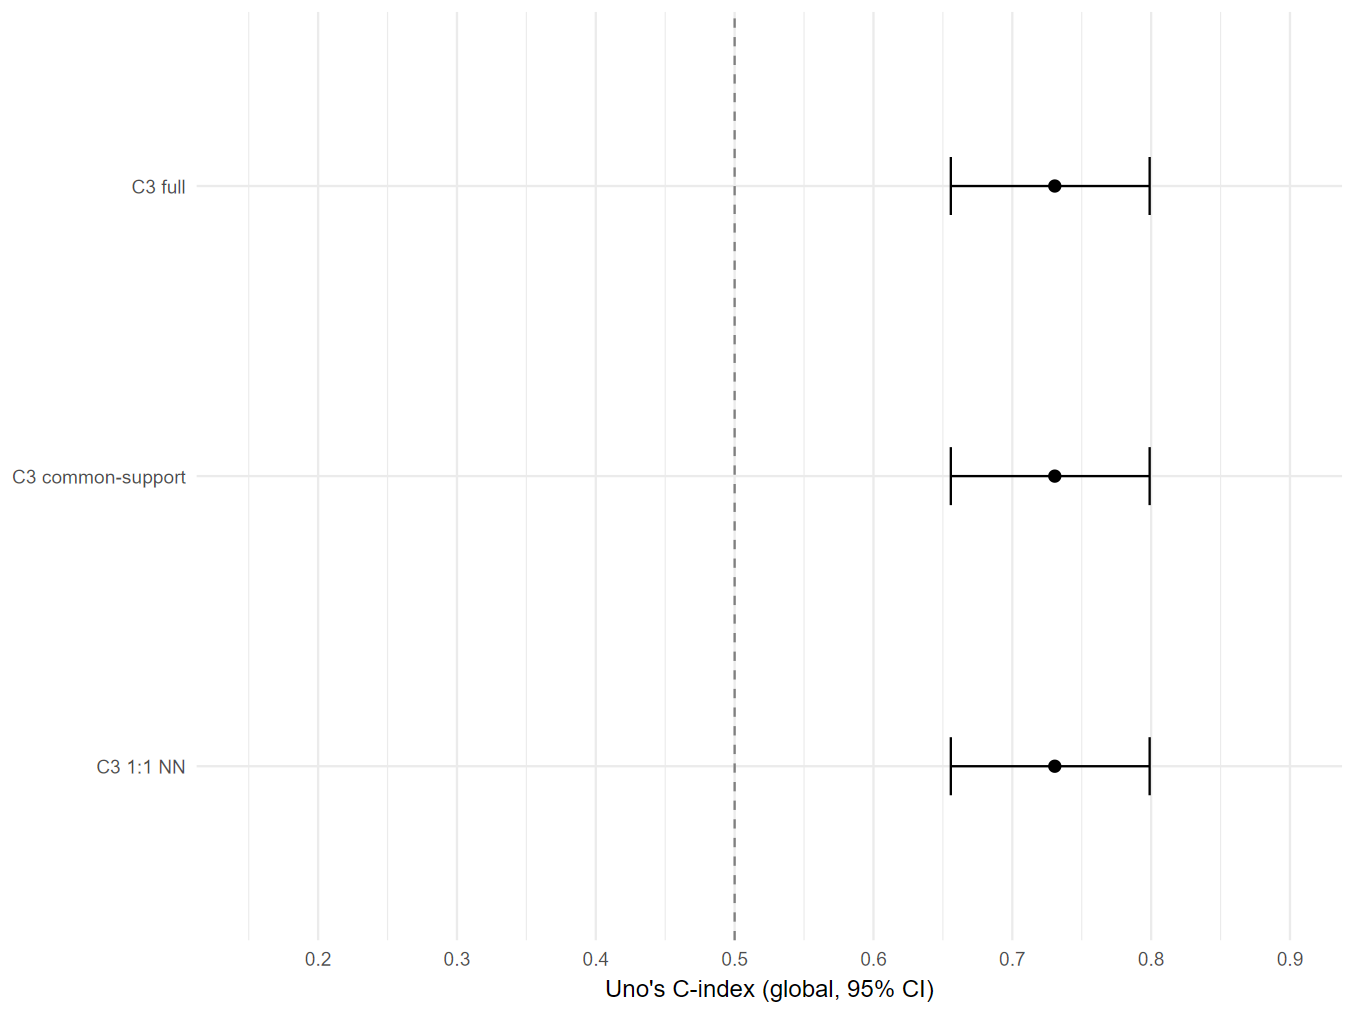

In [17]:
#| label: extval-cindex-plot
#| fig-width: 7
#| fig-height: 3.2

.t0 <- Sys.time()

gv <- function(boot, k) {
  r <- boot[boot$metric == k, ]
  if (nrow(r)) c(r$lo[1], r$hi[1]) else c(NA_real_, NA_real_)
}

labs <- c(
  "C3 full",
  "C3 common-support",
  "C3 1:1 NN"#,
  # "C5 full",
  # "C5 common-support",
  # "C5 1:1 NN"
)

cidf <- data.frame(
  cohort = factor(labs, levels = rev(labs)),
  cindex = c(
    res$C3$eval$summary$Value[1],
    res$C3$match$eval$summary$Value[1],
    res$C3$nn$eval$summary$Value[1]#,
    # res$C5$eval$summary$Value[1],
    # res$C5$match$eval$summary$Value[1],
    # res$C5$nn$eval$summary$Value[1]
  ),
  lo = c(
    gv(res$C3$boot, "c_global")[1],
    gv(res$C3$match$boot, "c_global")[1],
    gv(res$C3$nn$boot, "c_global")[1]#,
    # gv(res$C5$boot, "c_global")[1],
    # gv(res$C5$match$boot, "c_global")[1],
    # gv(res$C5$nn$boot, "c_global")[1]
  ),
  hi = c(
    gv(res$C3$boot, "c_global")[2],
    gv(res$C3$match$boot, "c_global")[2],
    gv(res$C3$nn$boot, "c_global")[2]
    # gv(res$C5$boot, "c_global")[2],
    # gv(res$C5$match$boot, "c_global")[2],
    # gv(res$C5$nn$boot, "c_global")[2]
  )
)

if (requireNamespace("ggplot2", quietly = TRUE)) {
  ggplot2::ggplot(cidf, ggplot2::aes(cindex, cohort)) +
    ggplot2::geom_vline(xintercept = 0.5, linetype = 2, color = "grey50") +
    ggplot2::geom_errorbar(
      ggplot2::aes(xmin = lo, xmax = hi),
      orientation = "y",
      width = 0.2
    ) +
    ggplot2::geom_point(size = 2.4) +
    ggplot2::scale_x_continuous(
      limits = c(0.15, 0.9),
      breaks = seq(0.2, 0.9, 0.1)
    ) +
    ggplot2::labs(
      x = "Uno's C-index (global, 95% CI)",
      y = NULL
      #title = "External mortality discrimination by convenio"
    ) +
    ggplot2::theme_minimal(base_size = 12)
} else {
  warning("Package 'ggplot2' is not available.")
}

cat("Elapsed time:", round(as.numeric(difftime(Sys.time(), .t0, units = "mins")), 3), "minutes\n")

### IBS, null and IBS under each convention

In [18]:
#| label: extval-ibs-skill-both-conventions
#| message: true
.t0 <- Sys.time()
# IBS, intercept-only null IBS and Brier skill for the external mortality cohorts, under BOTH
# conventions: the one prediction23 and this notebook currently use (nodes c(3,6,12,36,60),
# integral anchored at 3, divided by max - min) and the classical Graf definition (fine grid,
# anchored at 0, divided by the horizon). ONE censoring distribution serves both, so the
# difference between conventions isolates the integral and cannot be blamed on the weights.
suppressPackageStartupMessages(library(survival))
stopifnot(exists("res"), exists("project_root"))
# GUARD: refuse to run against the retired 13-variable death formula. The saved RDS of 2026-07-04
# was produced by formula_shap_death (no cohabitation terms); run_extval_death.R switched to
# formula_shap_death_rule2 on 2026-07-20. See handoff H43.
if (!grepl("rule2", res$model, fixed = TRUE)) {
  stop("res comes from the RETIRED death formula ('", res$model,
       "'). Re-run the extval-run cell before using this chunk.", call. = FALSE)
}
# Full run only. There is deliberately no reduced or test mode here.
IBS_B <- 1000L
IBS_SEED <- 2125L
IBS_STEP <- 0.25
IBS_HORIZONS <- c(3, 6, 12, 36, 60)
PRED23_NODES <- c(3, 6, 12, 36, 60)
G_MIN_IBS <- 0.05
stopifnot(IBS_B >= 1000L)
if (nzchar(Sys.getenv("PRED27_RUN_MODE", ""))) stop("PRED27_RUN_MODE is set; this notebook has no reduced mode.", call. = FALSE)
# Rebuild the development fits: run_extval_death() does not return them. build_dev_full() reads a
# cache, so this costs seconds, not minutes.
cat("Rebuilding development fits (cached)\n"); flush.console()
dev_list <- build_dev_full(verbose = FALSE)
fits <- fit_death_dev(dev_list, verbose = FALSE)
stopifnot(length(stats::coef(fits[[1]])) == 14L)
ibs_grid <- sort(unique(c(0, seq(IBS_STEP, max(IBS_HORIZONS), by = IBS_STEP), IBS_HORIZONS)))
grid_pos <- ibs_grid[ibs_grid > 0]
stopifnot(all(PRED23_NODES %in% grid_pos))
cat(sprintf("Fine grid: %d nodes, step %.2f months, anchored at 0.\n", length(ibs_grid), IBS_STEP))
# Trapezoid weights, CLASSICAL: nodes from 0 to h, b_0 = BS(0) = 0 by construction so the origin
# carries no weight, normalised by h.
.w_classical <- function(gp, horizons) {
  W <- matrix(0, length(gp), length(horizons))
  for (k in seq_along(horizons)) {
    keep <- which(gp <= horizons[k] + 1e-12)
    if (!length(keep)) next
    d <- diff(c(0, gp[keep])); m <- length(d); w <- d / 2
    if (m > 1L) w[seq_len(m - 1L)] <- w[seq_len(m - 1L)] + d[-1L] / 2
    W[keep, k] <- w / horizons[k]
  }
  W
}
# Trapezoid weights, CURRENT CONVENTION: only the reporting nodes truncated at h, integral
# anchored at min(nodes) = 3, normalised by max - min = h - 3. Two nodes minimum, so h = 3 is
# undefined and its column is all zero, which becomes NA downstream exactly as today.
.w_pred23 <- function(gp, horizons, nodes = PRED23_NODES) {
  W <- matrix(0, length(gp), length(horizons))
  for (k in seq_along(horizons)) {
    nk <- nodes[nodes <= horizons[k] + 1e-12]
    if (length(nk) < 2L) next
    idx <- match(nk, gp); stopifnot(!anyNA(idx))
    d <- diff(nk); W[idx, k] <- (c(d, 0) / 2 + c(0, d) / 2) / (max(nk) - min(nk))
  }
  W
}
W_cl <- .w_classical(grid_pos, IBS_HORIZONS); W_p23 <- .w_pred23(grid_pos, IBS_HORIZONS)
# Development marginal death curve: the deployable intercept-only null, estimated on development
# and predicted to every external patient. Outcome times are observed, not imputed, so imputation
# one suffices; asserted rather than assumed.
.dev_t <- as.numeric(dev_list[[1]]$death_time_from_disch_m)
.dev_e <- to01(dev_list[[1]]$death_event)
if (length(dev_list) > 1L) stopifnot(isTRUE(all.equal(.dev_t, as.numeric(dev_list[[2]]$death_time_from_disch_m))))
.km_dev <- survival::survfit(survival::Surv(.dev_t, .dev_e) ~ 1)
.null_curve <- as.numeric(summary(.km_dev, times = grid_pos, extend = TRUE)$surv)
# One cohort: predictions on the fine grid, per-subject IPCW Brier contributions, both integrals,
# null, skill, and a paired bootstrap. G is estimated on the cohort being evaluated, matching what
# ibs_ipcw_train(dat, dat, ...) already does inside evaluate_extval_death().
ibs_skill_one <- function(nondum, label) {
  dat <- dummify_extval_death(nondum, complete_case = TRUE, verbose = FALSE)
  tt <- as.numeric(dat$death_time_from_disch_m); ee <- to01(dat$death_event); n <- length(tt)
  surv <- predict_death_pooled(fits, dat, grid_pos)$surv_mat
  gfit <- survival::survfit(survival::Surv(tt, 1L - ee) ~ 1)
  G_at <- function(x) {
    req <- pmax(as.numeric(x), 0); u <- sort(unique(req))
    g <- as.numeric(summary(gfit, times = u, extend = TRUE)$surv)
    pmax(g[match(req, u)], G_MIN_IBS)
  }
  contrib <- function(S) {
    ge <- G_at(pmax(tt - 1e-8, 0)); out <- matrix(0, n, length(grid_pos))
    for (j in seq_along(grid_pos)) {
      t0 <- grid_pos[j]
      w <- ifelse(tt <= t0 & ee == 1L, 1 / ge, ifelse(tt > t0, 1 / G_at(t0), 0))
      out[, j] <- w * (as.numeric(tt > t0) - S[, j])^2
    }
    out
  }
  Cm <- contrib(surv)
  Cn <- contrib(matrix(.null_curve, n, length(grid_pos), byrow = TRUE))
  CW <- list(cl_m = Cm %*% W_cl, cl_n = Cn %*% W_cl, p23_m = Cm %*% W_p23, p23_n = Cn %*% W_p23)
  set.seed(IBS_SEED)
  idx <- lapply(seq_len(IBS_B), function(b) tabulate(sample.int(n, n, replace = TRUE), nbins = n))
  bt <- lapply(CW, function(M) t(vapply(idx, function(cnt) as.numeric(cnt %*% M) / n, numeric(ncol(M)))))
  q <- function(M, p) apply(M, 2, stats::quantile, p, na.rm = TRUE, names = FALSE)
  pt <- function(m) as.numeric(colMeans(CW[[m]]))
  # A horizon is undefined under a convention when that convention's weight column is
  # all zero, which happens for h = 3 under the current convention (a single node cannot
  # be integrated). Detect it from the weights rather than by testing whether the value
  # came out as exactly 0, which would also null a legitimate zero.
  undef <- list(cl_m = colSums(W_cl) == 0, cl_n = colSums(W_cl) == 0,
                p23_m = colSums(W_p23) == 0, p23_n = colSums(W_p23) == 0)
  mk <- function(conv, mm, nn) {
    sk <- 1 - bt[[mm]] / bt[[nn]]
    ibs <- pt(mm); ibs[undef[[mm]]] <- NA_real_; nul <- pt(nn); nul[undef[[nn]]] <- NA_real_
    data.frame(cohort = label, convention = conv, horizon_months = IBS_HORIZONS,
               ibs = ibs, ibs_lo = q(bt[[mm]], 0.025), ibs_hi = q(bt[[mm]], 0.975),
               ibs_null = nul, skill = 1 - ibs / nul,
               skill_lo = q(sk, 0.025), skill_hi = q(sk, 0.975),
               stringsAsFactors = FALSE, row.names = NULL)
  }
  # Paired difference BETWEEN conventions on the same cohort and the same resamples: this is the
  # contrast that isolates the integral, and it is the only genuinely paired comparison available
  # in this notebook (the matched subsamples are different patient subsets, not re-scorings).
  dconv <- bt$p23_m - bt$cl_m
  conv_delta <- data.frame(cohort = label, horizon_months = IBS_HORIZONS,
    ibs_current = pt("p23_m"), ibs_classical = pt("cl_m"),
    delta = pt("p23_m") - pt("cl_m"),
    delta_lo = q(dconv, 0.025), delta_hi = q(dconv, 0.975),
    pct_inflation = 100 * (pt("p23_m") / pt("cl_m") - 1),
    stringsAsFactors = FALSE, row.names = NULL)
  conv_delta[colSums(W_p23) == 0, c("ibs_current", "delta", "delta_lo", "delta_hi", "pct_inflation")] <- NA_real_
  list(skill = rbind(mk("current (nodes, anchored at 3)", "p23_m", "p23_n"),
                     mk("classical (fine grid, from 0)", "cl_m", "cl_n")),
       conv = conv_delta, n = n, deaths = sum(ee == 1L))
}
cohorts <- list("Convenio 3 (full)" = res$C3$nondum_cc,
                "Convenio 3 (common support)" = res$C3$nondum_matched,
                "Convenio 3 (1:1 NN)" = res$C3$nondum_nn)
out_list <- list()
for (nm in names(cohorts)) {
  cat(sprintf("\n--- %s ---\n", nm)); flush.console()
  out_list[[nm]] <- ibs_skill_one(cohorts[[nm]], nm)
  cat(sprintf("n = %d, deaths = %d\n", out_list[[nm]]$n, out_list[[nm]]$deaths)); flush.console()
}
ibs_skill_death <- do.call(rbind, lapply(out_list, `[[`, "skill"))
conv_delta_death <- do.call(rbind, lapply(out_list, `[[`, "conv"))
rownames(ibs_skill_death) <- NULL; rownames(conv_delta_death) <- NULL
show_kable(knitr::kable(ibs_skill_death, "markdown", digits = 6,
  caption = "External mortality IBS, intercept-only null IBS and Brier skill under both conventions, with patient-bootstrap 95% intervals. The null is the development-cohort marginal Kaplan-Meier survival predicted to every external patient. Brier skill is nearly uninformative for a rare outcome at short horizons, because the null already tracks the cumulative incidence; read it alongside discrimination, not instead of it."))
show_kable(knitr::kable(conv_delta_death, "markdown", digits = 6,
  caption = "Paired difference between the two IBS conventions on the same cohort and the same resamples. This isolates the integral: the censoring weights are identical in both columns. The 3-month row is empty because the current convention cannot integrate a single node."))
out_dir <- file.path(project_root, "data", "20241015_out", "pred27")
dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)
utils::write.csv(ibs_skill_death, file.path(out_dir, "extval_death_ibs_skill_both_conventions.csv"), row.names = FALSE)
utils::write.csv(conv_delta_death, file.path(out_dir, "extval_death_convention_delta.csv"), row.names = FALSE)
cat(sprintf("\nIBS/skill completed in %.2f minutes.\n", as.numeric(difftime(Sys.time(), .t0, units = "mins")))); flush.console()

Rebuilding development fits (cached)
Fine grid: 241 nodes, step 0.25 months, anchored at 0.

--- Convenio 3 (full) ---
n = 605, deaths = 71

--- Convenio 3 (common support) ---
n = 605, deaths = 71

--- Convenio 3 (1:1 NN) ---
n = 605, deaths = 71


Table: External mortality IBS, intercept-only null IBS and Brier skill under both conventions, with patient-bootstrap 95% intervals. The null is the development-cohort marginal Kaplan-Meier survival predicted to every external patient. Brier skill is nearly uninformative for a rare outcome at short horizons, because the null already tracks the cumulative incidence; read it alongside discrimination, not instead of it.

|cohort                      |convention                     | horizon_months|      ibs|   ibs_lo|   ibs_hi| ibs_null|     skill|  skill_lo| skill_hi|
|:---------------------------|:------------------------------|--------------:|--------:|--------:|--------:|--------:|---------:|---------:|--------:|
|Convenio 3 (full)        

In [27]:
#| label: extval-ibs-ci-sensitivity-resampled-g
.t0 <- Sys.time()
# SENSITIVITY ON THE INTERVAL, NOT ON THE ESTIMATE. The primary chunk holds the censoring
# distribution G fixed at its full-sample estimate and resamples only the precomputed per-subject
# contributions. That is what makes B = 1000 on a 240-node grid affordable, and it keeps the paired
# comparison BETWEEN conventions exact, because both are then weighted identically. What it does not
# do is propagate the uncertainty of having ESTIMATED G, so the marginal intervals are narrower than
# they should be by an unknown amount. This chunk re-estimates G inside every replicate and prints
# both widths side by side. Point estimates are untouched: they stay the full-sample values from the
# primary chunk, so no headline number moves.
# NOT resampled here, deliberately: the development null curve. It is an external, deployable
# quantity estimated on the development cohort, and the primary chunk treats it the same way, so
# holding it fixed keeps the two runs comparable instead of confounding two changes at once.
suppressPackageStartupMessages(library(survival))
stopifnot(exists("res"), exists("fits"), exists("grid_pos"), exists("W_cl"), exists("W_p23"),
          exists(".null_curve"), exists("ibs_skill_death"), exists("IBS_B"), exists("IBS_SEED"),
          exists("IBS_HORIZONS"), exists("G_MIN_IBS"), exists("to01"))
stopifnot(IBS_B >= 1000L)
if (nzchar(Sys.getenv("PRED27_RUN_MODE", ""))) stop("PRED27_RUN_MODE is set; this notebook has no reduced mode.", call. = FALSE)
# Convention labels are READ from the primary chunk's output rather than retyped. Retyping them is
# how the first version of this chunk failed: the merge below is keyed on the label, so a single
# differing word silently halves the joined table instead of erroring where the typo lives.
CONV_LABEL_CLASSICAL <- grep("classical", unique(ibs_skill_death$convention), value = TRUE)
CONV_LABEL_CURRENT <- grep("current", unique(ibs_skill_death$convention), value = TRUE)
stopifnot(length(CONV_LABEL_CLASSICAL) == 1L, length(CONV_LABEL_CURRENT) == 1L)
cat("Convention labels taken from the primary chunk:\n  ", CONV_LABEL_CLASSICAL, "\n  ", CONV_LABEL_CURRENT, "\n")
# Fast Kaplan-Meier step function for the CENSORING distribution. The primary chunk evaluates G with
# summary(survfit, times =, extend = TRUE), which is correct but far too slow to call 1000 times.
# This returns the same step function via findInterval: S(x) is the KM value at the largest event
# time not exceeding x, and 1 before the first one. The equality is asserted below rather than
# assumed, because a silent mismatch here would make the sensitivity incomparable to the primary.
.g_step <- function(time, event, g_min = G_MIN_IBS) {
  f <- survival::survfit(survival::Surv(time, 1L - event) ~ 1, conf.type = "none")
  ft <- f$time; fs <- f$surv
  function(x) {
    if (!length(ft)) return(rep(1, length(x)))
    i <- findInterval(as.numeric(x), ft)
    v <- rep(1, length(x))
    v[i > 0L] <- fs[i[i > 0L]]
    pmax(v, g_min)
  }
}
# One cohort, both G designs, on the SAME resamples.
ibs_ci_two_designs <- function(nondum, label) {
  dat <- dummify_extval_death(nondum, complete_case = TRUE, verbose = FALSE)
  tt <- as.numeric(dat$death_time_from_disch_m); ee <- to01(dat$death_event); n <- length(tt)
  surv <- predict_death_pooled(fits, dat, grid_pos)$surv_mat
  ng <- length(grid_pos); H <- length(IBS_HORIZONS)
  # Verify the fast G reproduces the slow one used by the primary chunk, on the full sample, at
  # every point either design ever queries. Tolerance is exact equality up to floating point.
  gfit <- survival::survfit(survival::Surv(tt, 1L - ee) ~ 1)
  .g_slow <- function(x) {
    req <- pmax(as.numeric(x), 0); u <- sort(unique(req))
    g <- as.numeric(summary(gfit, times = u, extend = TRUE)$surv)
    pmax(g[match(req, u)], G_MIN_IBS)
  }
  .g_fast <- .g_step(tt, ee)
  .probe <- c(grid_pos, pmax(tt - 1e-8, 0))
  .err <- max(abs(.g_slow(.probe) - .g_fast(.probe)))
  if (.err > 1e-12)
    stop(sprintf("Fast and slow G disagree by %.3e in %s; the sensitivity would not be comparable to the primary.", .err, label), call. = FALSE)
  # Per-subject contributions averaged over subjects, given a G. Returns the four column means of
  # the trapezoided integrals, which is all a replicate needs: colMeans(C %*% W) equals
  # colMeans(C) %*% W, so the n x grid matrix never has to be formed.
  cbar <- function(t_, e_, S_, G) {
    ge <- G(pmax(t_ - 1e-8, 0)); gg <- G(grid_pos)
    cm <- numeric(ng); cn <- numeric(ng)
    for (j in seq_len(ng)) {
      t0 <- grid_pos[j]
      alive <- t_ > t0
      w <- ifelse(!alive & e_ == 1L, 1 / ge, ifelse(alive, 1 / gg[j], 0))
      y <- as.numeric(alive)
      cm[j] <- mean(w * (y - S_[, j])^2)
      cn[j] <- mean(w * (y - .null_curve[j])^2)
    }
    list(m = cm, n = cn)
  }
  # The same resamples as the primary chunk. The primary draws sample.int(n, n, TRUE) B times after
  # set.seed(IBS_SEED) and then tabulates; drawing the raw indices under the same seed reproduces it
  # exactly, and the fixed-G arm recomputed below is what proves it.
  set.seed(IBS_SEED)
  idx_rows <- lapply(seq_len(IBS_B), function(b) sample.int(n, n, replace = TRUE))
  Wl <- list(cl = W_cl, p23 = W_p23)
  bt <- list(cl_m = matrix(NA_real_, IBS_B, H), cl_n = matrix(NA_real_, IBS_B, H),
             p23_m = matrix(NA_real_, IBS_B, H), p23_n = matrix(NA_real_, IBS_B, H))
  bt_fix <- bt
  G_full <- .g_fast
  for (b in seq_len(IBS_B)) {
    i <- idx_rows[[b]]
    t_ <- tt[i]; e_ <- ee[i]; S_ <- surv[i, , drop = FALSE]
    # Arm A, the primary design: G frozen at the full-sample estimate.
    a <- cbar(t_, e_, S_, G_full)
    bt_fix$cl_m[b, ] <- a$m %*% W_cl; bt_fix$cl_n[b, ] <- a$n %*% W_cl
    bt_fix$p23_m[b, ] <- a$m %*% W_p23; bt_fix$p23_n[b, ] <- a$n %*% W_p23
    # Arm B, the sensitivity: G re-estimated on the replicate itself.
    r <- cbar(t_, e_, S_, .g_step(t_, e_))
    bt$cl_m[b, ] <- r$m %*% W_cl; bt$cl_n[b, ] <- r$n %*% W_cl
    bt$p23_m[b, ] <- r$m %*% W_p23; bt$p23_n[b, ] <- r$n %*% W_p23
    if (b %% 100L == 0L) { cat(sprintf("  %s: %d/%d\n", label, b, IBS_B)); flush.console() }
  }
  q <- function(M, p) apply(M, 2, stats::quantile, p, na.rm = TRUE, names = FALSE)
  undef <- list(cl = colSums(W_cl) == 0, p23 = colSums(W_p23) == 0)
  mk <- function(conv, key) {
    lo_f <- q(bt_fix[[paste0(key, "_m")]], 0.025); hi_f <- q(bt_fix[[paste0(key, "_m")]], 0.975)
    lo_r <- q(bt[[paste0(key, "_m")]], 0.025);     hi_r <- q(bt[[paste0(key, "_m")]], 0.975)
    u <- undef[[key]]
    lo_f[u] <- NA_real_; hi_f[u] <- NA_real_; lo_r[u] <- NA_real_; hi_r[u] <- NA_real_
    data.frame(cohort = label, convention = conv, horizon_months = IBS_HORIZONS,
               ibs_lo_fixed_g = lo_f, ibs_hi_fixed_g = hi_f,
               ibs_lo_resampled_g = lo_r, ibs_hi_resampled_g = hi_r,
               width_fixed_g = hi_f - lo_f, width_resampled_g = hi_r - lo_r,
               width_ratio = (hi_r - lo_r) / (hi_f - lo_f),
               stringsAsFactors = FALSE, row.names = NULL)
  }
  # The paired between-convention difference under both designs. The point of showing it is that the
  # delta should be essentially unaffected: within a replicate both conventions share whatever G that
  # replicate produced, so the contrast still isolates the quadrature and nothing else.
  d_fix <- bt_fix$p23_m - bt_fix$cl_m
  d_res <- bt$p23_m - bt$cl_m
  dd <- data.frame(cohort = label, horizon_months = IBS_HORIZONS,
                   delta_lo_fixed_g = q(d_fix, 0.025), delta_hi_fixed_g = q(d_fix, 0.975),
                   delta_lo_resampled_g = q(d_res, 0.025), delta_hi_resampled_g = q(d_res, 0.975),
                   stringsAsFactors = FALSE, row.names = NULL)
  dd[undef$p23 | undef$cl, setdiff(names(dd), c("cohort", "horizon_months"))] <- NA_real_
  list(ci = rbind(mk(CONV_LABEL_CLASSICAL, "cl"), mk(CONV_LABEL_CURRENT, "p23")),
       delta = dd, n = n, deaths = sum(ee == 1L))
}
cohorts_g <- list("Convenio 3 (full)" = res$C3$nondum_cc,
                  "Convenio 3 (common support)" = res$C3$nondum_matched,
                  "Convenio 3 (1:1 NN)" = res$C3$nondum_nn)
g_list <- list()
for (nm in names(cohorts_g)) {
  cat(sprintf("\n--- %s ---\n", nm)); flush.console()
  g_list[[nm]] <- ibs_ci_two_designs(cohorts_g[[nm]], nm)
  cat(sprintf("n = %d, deaths = %d\n", g_list[[nm]]$n, g_list[[nm]]$deaths)); flush.console()
}
ibs_ci_g_sensitivity <- do.call(rbind, lapply(g_list, `[[`, "ci"))
ibs_delta_g_sensitivity <- do.call(rbind, lapply(g_list, `[[`, "delta"))
# FAILABLE CHECK. The fixed-G arm recomputed here must reproduce the intervals the primary chunk
# already reported. If it does not, this chunk is not drawing the same resamples or not weighting
# identically, and the comparison of widths would be meaningless. This is the assertion that makes
# the whole table interpretable, so it aborts rather than warns.
.ref <- ibs_skill_death[, c("cohort", "convention", "horizon_months", "ibs_lo", "ibs_hi")]
# Diagnose a key mismatch BEFORE merging. merge() drops non-matching rows silently, so a row-count
# assertion on its result reports that something is wrong without saying what, which is exactly the
# failure mode this block exists to prevent.
.k <- function(d) paste(d$cohort, d$convention, d$horizon_months, sep = " | ")
.only_here <- setdiff(.k(ibs_ci_g_sensitivity), .k(.ref))
.only_ref <- setdiff(.k(.ref), .k(ibs_ci_g_sensitivity))
if (length(.only_here) || length(.only_ref)) {
  cat("Keys present only in this chunk:\n"); print(utils::head(.only_here, 10))
  cat("Keys present only in the primary chunk:\n"); print(utils::head(.only_ref, 10))
  stop(sprintf("Join keys do not line up: %d unmatched here, %d unmatched in the primary output. The cohort names, the convention labels or the horizons differ between the two chunks.",
               length(.only_here), length(.only_ref)), call. = FALSE)
}
.cmp <- merge(ibs_ci_g_sensitivity, .ref, by = c("cohort", "convention", "horizon_months"))
stopifnot(nrow(.cmp) == nrow(ibs_ci_g_sensitivity))
.d1 <- max(abs(.cmp$ibs_lo_fixed_g - .cmp$ibs_lo), na.rm = TRUE)
.d2 <- max(abs(.cmp$ibs_hi_fixed_g - .cmp$ibs_hi), na.rm = TRUE)
cat(sprintf("\nReplication of the primary fixed-G intervals: max |lower| error %.3e, max |upper| error %.3e\n", .d1, .d2))
if (max(.d1, .d2) > 1e-10)
  stop("The fixed-G arm does not reproduce the primary chunk's intervals, so the two designs are not on the same resamples. Do not report this table.", call. = FALSE)
show_kable(knitr::kable(ibs_ci_g_sensitivity, "markdown", digits = 5, row.names = FALSE,
  caption = "Sensitivity of the IBS interval to holding the censoring distribution fixed. The fixed-G columns are the intervals already reported, reproduced here on the same resamples as a check. The resampled-G columns re-estimate the censoring distribution inside every bootstrap replicate and therefore propagate the uncertainty of having estimated it. Point estimates are identical under both designs and are not repeated here. width_ratio above 1 is the factor by which the reported interval was too narrow."))
show_kable(knitr::kable(ibs_delta_g_sensitivity, "markdown", digits = 5, row.names = FALSE,
  caption = "Paired difference between the two integration conventions, under both censoring designs. Within a replicate both conventions share the same censoring distribution, so this contrast isolates the quadrature under either design and should be essentially unchanged. A materially different interval here would mean the convention contrast was absorbing censoring variability, which it should not."))
if (exists("out_dir")) {
  utils::write.csv(ibs_ci_g_sensitivity, file.path(out_dir, "extval_death_ibs_ci_g_sensitivity.csv"), row.names = FALSE)
  utils::write.csv(ibs_delta_g_sensitivity, file.path(out_dir, "extval_death_ibs_delta_g_sensitivity.csv"), row.names = FALSE)
}
cat(sprintf("\nG-design sensitivity completed in %.2f minutes.\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))
flush.console()

Convention labels taken from the primary chunk:
   classical (fine grid, from 0) 
   current (nodes, anchored at 3) 

--- Convenio 3 (full) ---
  Convenio 3 (full): 100/1000
  Convenio 3 (full): 200/1000
  Convenio 3 (full): 300/1000
  Convenio 3 (full): 400/1000
  Convenio 3 (full): 500/1000
  Convenio 3 (full): 600/1000
  Convenio 3 (full): 700/1000
  Convenio 3 (full): 800/1000
  Convenio 3 (full): 900/1000
  Convenio 3 (full): 1000/1000
n = 605, deaths = 71

--- Convenio 3 (common support) ---
  Convenio 3 (common support): 100/1000
  Convenio 3 (common support): 200/1000
  Convenio 3 (common support): 300/1000
  Convenio 3 (common support): 400/1000
  Convenio 3 (common support): 500/1000
  Convenio 3 (common support): 600/1000
  Convenio 3 (common support): 700/1000
  Convenio 3 (common support): 800/1000
  Convenio 3 (common support): 900/1000
  Convenio 3 (common support): 1000/1000
n = 605, deaths = 71

--- Convenio 3 (1:1 NN) ---
  Convenio 3 (1:1 NN): 100/1000
  Convenio 3 (

### Somers' D and Uno'c by cohort

In [19]:
#| label: extval-unoc-somers
.t0 <- Sys.time()
# Risk-based Uno's C by cohort, with its Somers' D rescaling, plus an empirical check of the
# constant-marker null. Convenio 5 is included here because discrimination is the one thing it
# can support; IBS and calibration are not computed for it (too few deaths).
stopifnot(exists("fits"), exists("IBS_HORIZONS"), exists("IBS_B"), exists("IBS_SEED"), exists("out_dir"))
unoc_one <- function(nondum, label, B = IBS_B, seed = IBS_SEED) {
  dat <- dummify_extval_death(nondum, complete_case = TRUE, verbose = FALSE)
  tt <- as.numeric(dat$death_time_from_disch_m); ee <- to01(dat$death_event); n <- length(tt)
  risk <- predict_death_pooled(fits, dat, IBS_HORIZONS)$risk_mat
  one <- function(r, h, ix = NULL) {
    t <- if (is.null(ix)) tt else tt[ix]; e <- if (is.null(ix)) ee else ee[ix]
    s <- if (is.null(ix)) r else r[ix]
    if (sum(e == 1L & t <= h) < 2L) return(NA_real_)
    tryCatch(survival::concordance(survival::Surv(t, e) ~ s, timewt = "n/G2",
                                   reverse = TRUE, ymax = h)$concordance,
             error = function(z) NA_real_)
  }
  cs <- vapply(seq_along(IBS_HORIZONS), function(j) one(risk[, j], IBS_HORIZONS[j]), numeric(1))
  # The C null is a constant marker: every pair ties, so concordance must be exactly 0.5 by
  # construction. Computed rather than assumed, so the Somers' D column can be discarded if it
  # ever fails to hold.
  cnull <- vapply(seq_along(IBS_HORIZONS), function(j) one(rep(0.5, n), IBS_HORIZONS[j]), numeric(1))
  set.seed(seed)
  M <- matrix(NA_real_, B, length(IBS_HORIZONS))
  for (b in seq_len(B)) {
    ix <- sample.int(n, n, replace = TRUE)
    M[b, ] <- vapply(seq_along(IBS_HORIZONS), function(j) one(risk[, j], IBS_HORIZONS[j], ix), numeric(1))
  }
  lo <- apply(M, 2, stats::quantile, 0.025, na.rm = TRUE, names = FALSE)
  hi <- apply(M, 2, stats::quantile, 0.975, na.rm = TRUE, names = FALSE)
  data.frame(cohort = label, horizon_months = IBS_HORIZONS, n = n, deaths = sum(ee == 1L),
             uno_c = cs, uno_c_lo = lo, uno_c_hi = hi, uno_c_null = cnull,
             somers_d = 2 * cs - 1, somers_d_lo = 2 * lo - 1, somers_d_hi = 2 * hi - 1,
             stringsAsFactors = FALSE, row.names = NULL)
}
unoc_cohorts <- list("Convenio 3 (full)" = res$C3$nondum_cc,
                     "Convenio 3 (common support)" = res$C3$nondum_matched,
                     "Convenio 3 (1:1 NN)" = res$C3$nondum_nn,
                     "Convenio 5 (full)" = res$C5$nondum_cc)
unoc_death <- do.call(rbind, lapply(names(unoc_cohorts), function(nm) {
  cat(sprintf("Uno C: %s\n", nm)); flush.console()
  unoc_one(unoc_cohorts[[nm]], nm)
}))
rownames(unoc_death) <- NULL
stopifnot(all(is.na(unoc_death$uno_c_null) | abs(unoc_death$uno_c_null - 0.5) < 1e-8))
cat("Confirmed on these cohorts: the constant-marker null C is 0.5, so somers_d IS the C skill\n")
cat("and carries no information beyond uno_c. Report it as Somers' D, never as the analogue of\n")
cat("the Brier skill score, whose null is estimated from data rather than fixed by construction.\n")
show_kable(knitr::kable(unoc_death, "markdown", digits = 4,
  caption = "External mortality discrimination by cohort: risk-based Uno's C at each horizon with patient-bootstrap 95% intervals, the constant-marker null, and the Somers' D rescaling. No paired difference between cohorts is reported because the matched subsamples are different patient subsets, not alternative scorings of the same patients, so a paired contrast between them would have no interpretation."))
utils::write.csv(unoc_death, file.path(out_dir, "extval_death_unoc_somers.csv"), row.names = FALSE)
cat(sprintf("\nUno C completed in %.2f minutes.\n", as.numeric(difftime(Sys.time(), .t0, units = "mins")))); flush.console()

Uno C: Convenio 3 (full)
Uno C: Convenio 3 (common support)
Uno C: Convenio 3 (1:1 NN)
Uno C: Convenio 5 (full)
Confirmed on these cohorts: the constant-marker null C is 0.5, so somers_d IS the C skill
and carries no information beyond uno_c. Report it as Somers' D, never as the analogue of
the Brier skill score, whose null is estimated from data rather than fixed by construction.


Table: External mortality discrimination by cohort: risk-based Uno's C at each horizon with patient-bootstrap 95% intervals, the constant-marker null, and the Somers' D rescaling. No paired difference between cohorts is reported because the matched subsamples are different patient subsets, not alternative scorings of the same patients, so a paired contrast between them would have no interpretation.

|cohort                      | horizon_months|    n| deaths|  uno_c| uno_c_lo| uno_c_hi| uno_c_null| somers_d| somers_d_lo| somers_d_hi|
|:---------------------------|--------------:|----:|------:|------:|------

## Calibration (convenio 3)

Predicted mortality risk from the frozen Cox versus Kaplan-Meier observed risk (readmission and administrative end as censoring), in risk deciles. The integrated calibration index (ICI, the loess-smoothed mean absolute predicted-minus-observed difference) is the primary calibration metric; the expected:observed ratio is reported alongside. Convenio 5 is omitted (too few deaths for stable calibration).

In [20]:
#| label: extval-calibration-table
cal_tab <- function(cal, boot, label) {
  if (is.null(cal)) return(NULL)
  do.call(rbind, lapply(CAL_TIMES, function(h) {
    ps <- cal$pooled_summary[cal$pooled_summary$time_months == h, ]
    ir <- boot[boot$metric == paste0("ici_", h), ]
    er <- boot[boot$metric == paste0("eo_", h), ]
    data.frame(Cohort = label, `Horizon, mo` = h,
      `ICI (95% CI)` = sprintf("%.3f (%.3f, %.3f)", ps$ici_mean, ir$lo[1], ir$hi[1]),
      ECE = sprintf("%.3f", ps$ece_mean),
      `E:O (95% CI)` = sprintf("%.2f (%.2f, %.2f)", ps$eo_mean, er$lo[1], er$hi[1]),
      `Predicted` = sprintf("%.3f", ps$mean_pred),
      `Observed (KM)` = sprintf("%.3f", ps$observed),
      check.names = FALSE, stringsAsFactors = FALSE)
  }))
}
calib <- rbind(cal_tab(res$C3$cal, res$C3$boot, "Convenio 3 (full)"),
               cal_tab(res$C3$match$cal, res$C3$match$boot, "Convenio 3 (common support)"),
               cal_tab(res$C3$nn$cal, res$C3$nn$boot, "Convenio 3 (1:1 NN)"))
show_kable(knitr::kable(calib, "markdown",
  caption = "External mortality calibration, convenio 3: ICI (primary), ECE, expected:observed ratio, predicted vs observed (Kaplan-Meier). ICI is the integrated absolute predicted-minus-observed difference; E:O < 1 indicates under-prediction at that horizon."))



Table: External mortality calibration, convenio 3: ICI (primary), ECE, expected:observed ratio, predicted vs observed (Kaplan-Meier). ICI is the integrated absolute predicted-minus-observed difference; E:O < 1 indicates under-prediction at that horizon.

|Cohort                      | Horizon, mo|ICI (95% CI)         |ECE   |E:O (95% CI)      |Predicted |Observed (KM) |
|:---------------------------|-----------:|:--------------------|:-----|:-----------------|:---------|:-------------|
|Convenio 3 (full)           |           6|0.010 (0.005, 0.024) |0.016 |0.59 (0.39, 1.09) |0.014     |0.024         |
|Convenio 3 (full)           |          12|0.017 (0.008, 0.034) |0.018 |0.62 (0.44, 0.95) |0.026     |0.042         |
|Convenio 3 (full)           |          36|0.024 (0.015, 0.051) |0.022 |0.89 (0.69, 1.19) |0.082     |0.093         |
|Convenio 3 (full)           |          60|0.050 (0.027, 0.096) |0.049 |0.75 (0.61, 0.97) |0.132     |0.177         |
|Convenio 3 (common support) |     

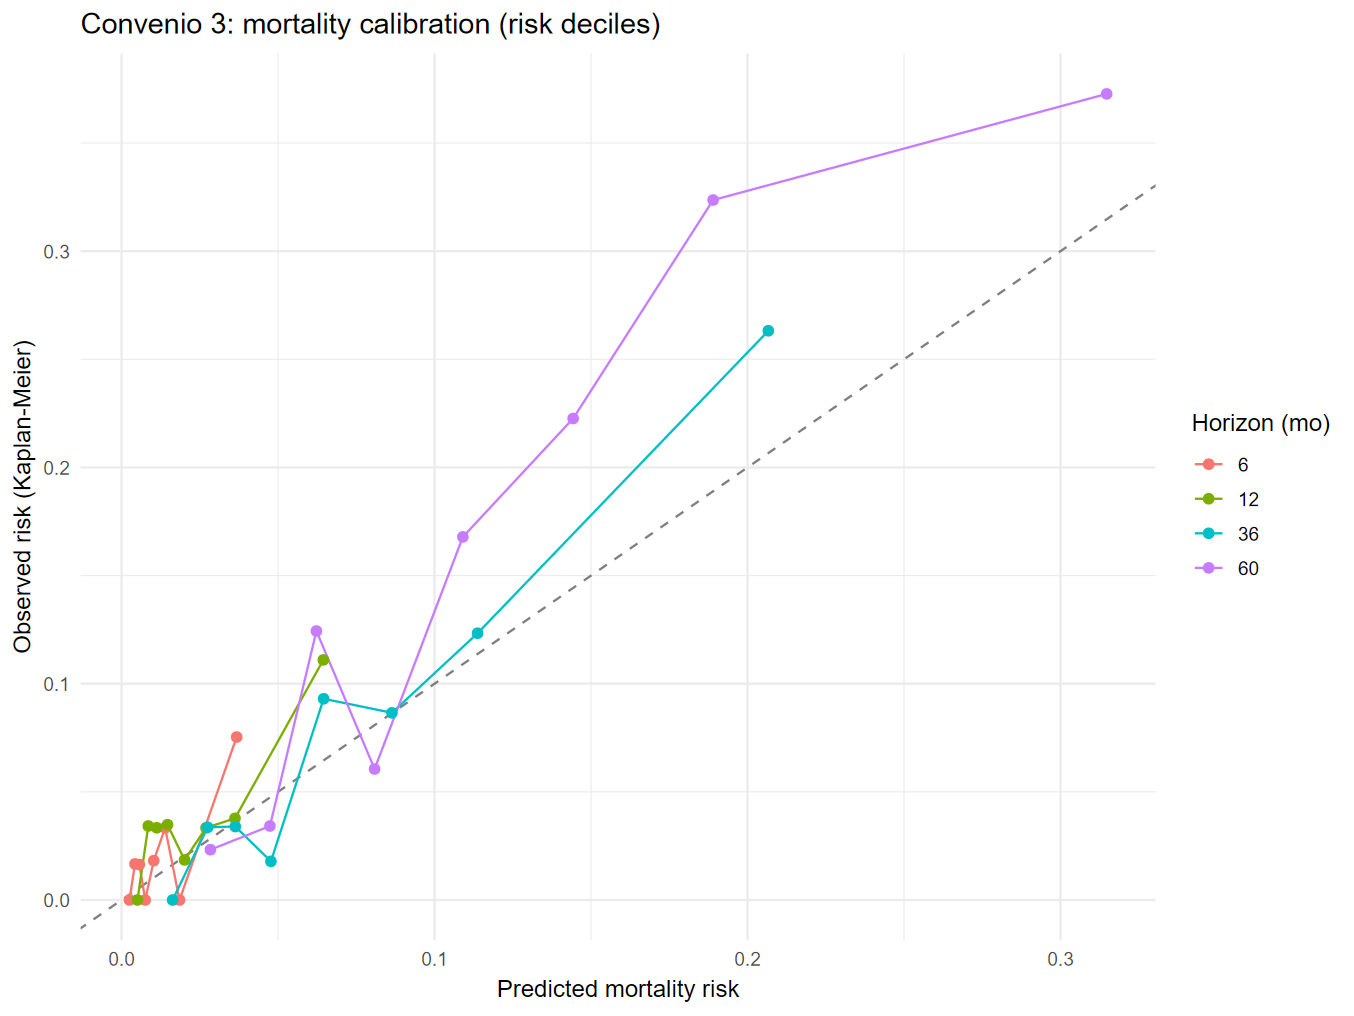

In [21]:
#| label: extval-calibration-curve
#| fig-width: 6.5
#| fig-height: 4.5
cc <- res$C3$cal$calibration_curves
if (!is.null(cc) && nrow(cc) && requireNamespace("ggplot2", quietly = TRUE)) {
  library(ggplot2)
  ggplot(cc, aes(mean_predicted, observed, color = factor(time_months))) +
    geom_abline(slope = 1, intercept = 0, linetype = 2, color = "grey50") +
    geom_line() + geom_point(size = 2) +
    labs(x = "Predicted mortality risk", y = "Observed risk (Kaplan-Meier)",
         color = "Horizon (mo)", title = "Convenio 3: mortality calibration (risk deciles)") +
    theme_minimal(base_size = 12)
} else {
  cat("No calibration curve available.\n")
}

In [28]:
#| label: extval-death-baseline-recalibration-update
cat("\n--- Baseline-hazard-only recalibration update (convenio 3, out-of-fold) ---\n")
source(file.path(project_root, "cons/_alt_scripts/extval_recalibration_update.R"))
B_BOOT_RECAL <- 1000L
K_RECAL <- 10L
cat("Bootstrap replicates for the recalibration comparison:", B_BOOT_RECAL, "\n")
cat("Cross-fitting folds:", K_RECAL, "\n")
cat("Scope: convenio 3 full cohort only (not the matched CS/NN subsamples; convenio 5 has too few deaths for any calibration exercise, discrimination-only as already established).\n")
flush.console()
time_c3 <- res$C3$nondum_cc$death_time_from_disch_m
event_c3 <- to01(res$C3$nondum_cc$death_event)
surv_cols_c3 <- match(CAL_TIMES, res$C3$eval$eval_times)
stopifnot(!anyNA(surv_cols_c3), nrow(res$C3$eval$surv_mat) == length(time_c3))
recal_compare_list_c3 <- vector("list", length(CAL_TIMES))
recal_boot_list_c3 <- vector("list", length(CAL_TIMES))
for (j in seq_along(CAL_TIMES)) {
  h <- CAL_TIMES[[j]]
  risk_h <- 1 - res$C3$eval$surv_mat[, surv_cols_c3[j]]
  cat("\nHorizon", h, "months...\n")
  flush.console()
  recal_compare_list_c3[[j]] <- recal_compare_frozen_vs_updated(time_c3, event_c3, risk_h, h, K = K_RECAL, seed = SEED)
  recal_boot_list_c3[[j]] <- recal_bootstrap_compare(time_c3, event_c3, risk_h, h, K = K_RECAL, B = B_BOOT_RECAL, seed = SEED, parallel = TRUE)
  recal_boot_list_c3[[j]]$horizon_months <- h
}
recal_compare_table_c3 <- dplyr::bind_rows(lapply(recal_compare_list_c3, function(x) x$table))
recal_fold_summary_c3 <- dplyr::bind_rows(Map(function(x, h) { fs <- x$fold_summary; fs$horizon_months <- h; fs }, recal_compare_list_c3, CAL_TIMES))
recal_boot_table_c3 <- dplyr::bind_rows(recal_boot_list_c3)
recal_n_fallback_c3 <- vapply(recal_compare_list_c3, function(x) x$n_fallback_folds, integer(1))
cat("\nFold-level fallback count (intercept could not be estimated, defaulted to 0) by horizon:\n")
print(stats::setNames(recal_n_fallback_c3, CAL_TIMES))
flush.console()
recal_display_c3 <- recal_compare_table_c3
recal_display_c3$expected_to_observed_lower95 <- NA_real_
recal_display_c3$expected_to_observed_upper95 <- NA_real_
recal_display_c3$ici_lower95 <- NA_real_
recal_display_c3$ici_upper95 <- NA_real_
recal_display_c3$ece_lower95 <- NA_real_
recal_display_c3$ece_upper95 <- NA_real_
recal_display_c3$calibration_slope_lower95 <- NA_real_
recal_display_c3$calibration_slope_upper95 <- NA_real_
for (j in seq_along(CAL_TIMES)) {
  h <- CAL_TIMES[[j]]
  b <- recal_boot_table_c3[recal_boot_table_c3$horizon_months == h, ]
  is_frozen <- recal_display_c3$horizon_months == h & recal_display_c3$model == "Frozen (as published)"
  is_updated <- recal_display_c3$horizon_months == h & recal_display_c3$model == "Baseline-updated (out-of-fold)"
  recal_display_c3$expected_to_observed_lower95[is_frozen] <- b$lower_95[b$metric == "frozen_eo"]
  recal_display_c3$expected_to_observed_upper95[is_frozen] <- b$upper_95[b$metric == "frozen_eo"]
  recal_display_c3$expected_to_observed_lower95[is_updated] <- b$lower_95[b$metric == "updated_eo"]
  recal_display_c3$expected_to_observed_upper95[is_updated] <- b$upper_95[b$metric == "updated_eo"]
  recal_display_c3$ici_lower95[is_frozen] <- b$lower_95[b$metric == "frozen_ici"]
  recal_display_c3$ici_upper95[is_frozen] <- b$upper_95[b$metric == "frozen_ici"]
  recal_display_c3$ici_lower95[is_updated] <- b$lower_95[b$metric == "updated_ici"]
  recal_display_c3$ici_upper95[is_updated] <- b$upper_95[b$metric == "updated_ici"]
  recal_display_c3$ece_lower95[is_frozen] <- b$lower_95[b$metric == "frozen_ece"]
  recal_display_c3$ece_upper95[is_frozen] <- b$upper_95[b$metric == "frozen_ece"]
  recal_display_c3$ece_lower95[is_updated] <- b$lower_95[b$metric == "updated_ece"]
  recal_display_c3$ece_upper95[is_updated] <- b$upper_95[b$metric == "updated_ece"]
  recal_display_c3$calibration_slope_lower95[is_updated] <- b$lower_95[b$metric == "updated_slope"]
  recal_display_c3$calibration_slope_upper95[is_updated] <- b$upper_95[b$metric == "updated_slope"]
}
show_kable(knitr::kable(recal_display_c3, "markdown", digits = 4,
  caption = "Convenio 3: frozen vs out-of-fold baseline-updated mortality risk. E:O, ICI, ECE and calibration slope with 95% bootstrap CI (10-fold cross-fitting)."))
recal_slope_flag_c3 <- recal_display_c3[recal_display_c3$model == "Baseline-updated (out-of-fold)", c("horizon_months", "calibration_slope", "calibration_slope_lower95", "calibration_slope_upper95")]
recal_slope_flag_c3$excludes_one <- with(recal_slope_flag_c3, (calibration_slope_lower95 > 1) | (calibration_slope_upper95 < 1))
cat("\nUpdated-model calibration slope 95% CI vs 1 (excludes 1 => a baseline-only update is likely NOT enough; consider a fuller re-estimation as a separate next step):\n")
print(recal_slope_flag_c3)
flush.console()
out_dir_recal_c3 <- file.path(project_root, "data", "20241015_out", "pred27")
utils::write.csv(recal_display_c3, file.path(out_dir_recal_c3, "extval_death_recalibration_update_c3.csv"), row.names = FALSE)
utils::write.csv(recal_fold_summary_c3, file.path(out_dir_recal_c3, "extval_death_recalibration_fold_summary_c3.csv"), row.names = FALSE)
cat("\nSaved recalibration update tables to", out_dir_recal_c3, "\n")



--- Baseline-hazard-only recalibration update (convenio 3, out-of-fold) ---
Bootstrap replicates for the recalibration comparison: 1000 
Cross-fitting folds: 10 
Scope: convenio 3 full cohort only (not the matched CS/NN subsamples; convenio 5 has too few deaths for any calibration exercise, discrimination-only as already established).

Horizon 6 months...

Horizon 12 months...

Horizon 36 months...

Horizon 60 months...

Fold-level fallback count (intercept could not be estimated, defaulted to 0) by horizon:
 6 12 36 60 
 0  0  0  0 


Table: Convenio 3: frozen vs out-of-fold baseline-updated mortality risk. E:O, ICI, ECE and calibration slope with 95% bootstrap CI (10-fold cross-fitting).

| horizon_months|model                          |   n| observed| mean_predicted| expected_to_observed|    ici|    ece| calibration_intercept| calibration_slope| calibration_slope_se| expected_to_observed_lower95| expected_to_observed_upper95| ici_lower95| ici_upper95| ece_lower95| ece_upper95| cali

In [ ]:
#| label: extval-ibs-skill-both-conventions-corr
#| message: true
.t0 <- Sys.time()
# IBS, intercept-only null IBS and Brier skill for the external mortality cohorts, under BOTH
# conventions: the one prediction23 and this notebook currently use (nodes c(3,6,12,36,60),
# integral anchored at 3, divided by max - min) and the classical Graf definition (fine grid,
# anchored at 0, divided by the horizon). ONE censoring distribution serves both, so the
# difference between conventions isolates the integral and cannot be blamed on the weights.
# UPDATED: the bootstrap now REFITS the censoring survival function G inside every replicate, on
# that replicate's own resampled (time, event), instead of reusing one G fit on the full cohort.
# Holding G fixed understates the interval, worst at 60 months where censoring-free follow-up in
# convenio 3 is thin. Point estimates are unaffected (they always used the full-sample G); only
# interval width can change. See cons/_alt_scripts/ibs_skill_bootstrap_refit_g.R.
suppressPackageStartupMessages(library(survival))
stopifnot(exists("res"), exists("project_root"))
source(file.path(project_root, "cons/_alt_scripts/ibs_skill_bootstrap_refit_g.R"))
# GUARD: refuse to run against the retired 13-variable death formula. The saved RDS of 2026-07-04
# was produced by formula_shap_death (no cohabitation terms); run_extval_death.R switched to
# formula_shap_death_rule2 on 2026-07-20. See handoff H43.
if (!grepl("rule2", res$model, fixed = TRUE)) {
  stop("res comes from the RETIRED death formula ('", res$model,
       "'). Re-run the extval-run cell before using this chunk.", call. = FALSE)
}
# Full run only. There is deliberately no reduced or test mode here.
IBS_B <- 1000L
IBS_SEED <- 2125L
IBS_STEP <- 0.25
IBS_HORIZONS <- c(3, 6, 12, 36, 60)
PRED23_NODES <- c(3, 6, 12, 36, 60)
G_MIN_IBS <- 0.05
stopifnot(IBS_B >= 1000L)
if (nzchar(Sys.getenv("PRED27_RUN_MODE", ""))) stop("PRED27_RUN_MODE is set; this notebook has no reduced mode.", call. = FALSE)
# Rebuild the development fits: run_extval_death() does not return them. build_dev_full() reads a
# cache, so this costs seconds, not minutes.
cat("Rebuilding development fits (cached)\n"); flush.console()
dev_list <- build_dev_full(verbose = FALSE)
fits <- fit_death_dev(dev_list, verbose = FALSE)
stopifnot(length(stats::coef(fits[[1]])) == 14L)
ibs_grid <- sort(unique(c(0, seq(IBS_STEP, max(IBS_HORIZONS), by = IBS_STEP), IBS_HORIZONS)))
grid_pos <- ibs_grid[ibs_grid > 0]
stopifnot(all(PRED23_NODES %in% grid_pos))
cat(sprintf("Fine grid: %d nodes, step %.2f months, anchored at 0.\n", length(ibs_grid), IBS_STEP))
# Trapezoid weights, CLASSICAL: nodes from 0 to h, b_0 = BS(0) = 0 by construction so the origin
# carries no weight, normalised by h.
.w_classical <- function(gp, horizons) {
  W <- matrix(0, length(gp), length(horizons))
  for (k in seq_along(horizons)) {
    keep <- which(gp <= horizons[k] + 1e-12)
    if (!length(keep)) next
    d <- diff(c(0, gp[keep])); m <- length(d); w <- d / 2
    if (m > 1L) w[seq_len(m - 1L)] <- w[seq_len(m - 1L)] + d[-1L] / 2
    W[keep, k] <- w / horizons[k]
  }
  W
}
# Trapezoid weights, CURRENT CONVENTION: only the reporting nodes truncated at h, integral
# anchored at min(nodes) = 3, normalised by max - min = h - 3. Two nodes minimum, so h = 3 is
# undefined and its column is all zero, which becomes NA downstream exactly as today.
.w_pred23 <- function(gp, horizons, nodes = PRED23_NODES) {
  W <- matrix(0, length(gp), length(horizons))
  for (k in seq_along(horizons)) {
    nk <- nodes[nodes <= horizons[k] + 1e-12]
    if (length(nk) < 2L) next
    idx <- match(nk, gp); stopifnot(!anyNA(idx))
    d <- diff(nk); W[idx, k] <- (c(d, 0) / 2 + c(0, d) / 2) / (max(nk) - min(nk))
  }
  W
}
W_cl <- .w_classical(grid_pos, IBS_HORIZONS); W_p23 <- .w_pred23(grid_pos, IBS_HORIZONS)
# Development marginal death curve: the deployable intercept-only null, estimated on development
# and predicted to every external patient. Outcome times are observed, not imputed, so imputation
# one suffices; asserted rather than assumed.
.dev_t <- as.numeric(dev_list[[1]]$death_time_from_disch_m)
.dev_e <- to01(dev_list[[1]]$death_event)
if (length(dev_list) > 1L) stopifnot(isTRUE(all.equal(.dev_t, as.numeric(dev_list[[2]]$death_time_from_disch_m))))
.km_dev <- survival::survfit(survival::Surv(.dev_t, .dev_e) ~ 1)
.null_curve <- as.numeric(summary(.km_dev, times = grid_pos, extend = TRUE)$surv)
# One cohort: predictions on the fine grid, per-subject IPCW Brier contributions (point estimate,
# fixed full-cohort G), both integrals, null, skill, and a bootstrap that refits G per replicate.
ibs_skill_one <- function(nondum, label) {
  dat <- dummify_extval_death(nondum, complete_case = TRUE, verbose = FALSE)
  tt <- as.numeric(dat$death_time_from_disch_m); ee <- to01(dat$death_event); n <- length(tt)
  surv <- predict_death_pooled(fits, dat, grid_pos)$surv_mat
  gfit <- survival::survfit(survival::Surv(tt, 1L - ee) ~ 1)
  G_at <- function(x) {
    req <- pmax(as.numeric(x), 0); u <- sort(unique(req))
    g <- as.numeric(summary(gfit, times = u, extend = TRUE)$surv)
    pmax(g[match(req, u)], G_MIN_IBS)
  }
  contrib <- function(S) {
    ge <- G_at(pmax(tt - 1e-8, 0)); out <- matrix(0, n, length(grid_pos))
    for (j in seq_along(grid_pos)) {
      t0 <- grid_pos[j]
      w <- ifelse(tt <= t0 & ee == 1L, 1 / ge, ifelse(tt > t0, 1 / G_at(t0), 0))
      out[, j] <- w * (as.numeric(tt > t0) - S[, j])^2
    }
    out
  }
  surv_null_mat <- matrix(.null_curve, n, length(grid_pos), byrow = TRUE)
  Cm <- contrib(surv)
  Cn <- contrib(surv_null_mat)
  CW <- list(cl_m = Cm %*% W_cl, cl_n = Cn %*% W_cl, p23_m = Cm %*% W_p23, p23_n = Cn %*% W_p23)
  # THE FIX: refit G inside every bootstrap replicate on that replicate's own resample, instead of
  # reweighting fixed contributions built from one full-cohort G. Point-estimate CW above is left
  # untouched (still the fixed full-cohort G, exactly like every other point estimate in this
  # notebook). This cohort self-generates its own resamples (IBS_SEED/IBS_B), matching this cell's
  # existing convention, since there is no shared bootstrap_indices object in prediction27.
  bt_new <- ibsskill_bootstrap_refit(tt, ee, surv, surv_null_mat, grid_pos,
    weight_list = list(cl = W_cl, p23 = W_p23), B = IBS_B, seed = IBS_SEED,
    g_min = G_MIN_IBS, parallel = TRUE)
  bt <- list(cl_m = bt_new$cl_model, cl_n = bt_new$cl_null, p23_m = bt_new$p23_model, p23_n = bt_new$p23_null)
  q <- function(M, p) apply(M, 2, stats::quantile, p, na.rm = TRUE, names = FALSE)
  pt <- function(m) as.numeric(colMeans(CW[[m]]))
  # A horizon is undefined under a convention when that convention's weight column is
  # all zero, which happens for h = 3 under the current convention (a single node cannot
  # be integrated). Detect it from the weights rather than by testing whether the value
  # came out as exactly 0, which would also null a legitimate zero.
  undef <- list(cl_m = colSums(W_cl) == 0, cl_n = colSums(W_cl) == 0,
                p23_m = colSums(W_p23) == 0, p23_n = colSums(W_p23) == 0)
  mk <- function(conv, mm, nn) {
    sk <- 1 - bt[[mm]] / bt[[nn]]
    ibs <- pt(mm); ibs[undef[[mm]]] <- NA_real_; nul <- pt(nn); nul[undef[[nn]]] <- NA_real_
    data.frame(cohort = label, convention = conv, horizon_months = IBS_HORIZONS,
               ibs = ibs, ibs_lo = q(bt[[mm]], 0.025), ibs_hi = q(bt[[mm]], 0.975),
               ibs_null = nul, skill = 1 - ibs / nul,
               skill_lo = q(sk, 0.025), skill_hi = q(sk, 0.975),
               stringsAsFactors = FALSE, row.names = NULL)
  }
  # Paired difference BETWEEN conventions on the same cohort and the same resamples: this is the
  # contrast that isolates the integral, and it is the only genuinely paired comparison available
  # in this notebook (the matched subsamples are different patient subsets, not re-scorings).
  dconv <- bt$p23_m - bt$cl_m
  conv_delta <- data.frame(cohort = label, horizon_months = IBS_HORIZONS,
    ibs_current = pt("p23_m"), ibs_classical = pt("cl_m"),
    delta = pt("p23_m") - pt("cl_m"),
    delta_lo = q(dconv, 0.025), delta_hi = q(dconv, 0.975),
    pct_inflation = 100 * (pt("p23_m") / pt("cl_m") - 1),
    stringsAsFactors = FALSE, row.names = NULL)
  conv_delta[colSums(W_p23) == 0, c("ibs_current", "delta", "delta_lo", "delta_hi", "pct_inflation")] <- NA_real_
  list(skill = rbind(mk("current (nodes, anchored at 3)", "p23_m", "p23_n"),
                     mk("classical (fine grid, from 0)", "cl_m", "cl_n")),
       conv = conv_delta, n = n, deaths = sum(ee == 1L))
}
cohorts <- list("Convenio 3 (full)" = res$C3$nondum_cc,
                "Convenio 3 (common support)" = res$C3$nondum_matched,
                "Convenio 3 (1:1 NN)" = res$C3$nondum_nn)
out_list <- list()
for (nm in names(cohorts)) {
  cat(sprintf("\n--- %s ---\n", nm)); flush.console()
  out_list[[nm]] <- ibs_skill_one(cohorts[[nm]], nm)
  cat(sprintf("n = %d, deaths = %d\n", out_list[[nm]]$n, out_list[[nm]]$deaths)); flush.console()
}
ibs_skill_death <- do.call(rbind, lapply(out_list, `[[`, "skill"))
conv_delta_death <- do.call(rbind, lapply(out_list, `[[`, "conv"))
rownames(ibs_skill_death) <- NULL; rownames(conv_delta_death) <- NULL
show_kable(knitr::kable(ibs_skill_death, "markdown", digits = 6,
  caption = "External mortality IBS, intercept-only null IBS and Brier skill under both conventions, with a patient bootstrap that refits the censoring distribution G inside every replicate. The null is the development-cohort marginal Kaplan-Meier survival predicted to every external patient. Brier skill is nearly uninformative for a rare outcome at short horizons, because the null already tracks the cumulative incidence; read it alongside discrimination, not instead of it."))
show_kable(knitr::kable(conv_delta_death, "markdown", digits = 6,
  caption = "Paired difference between the two IBS conventions on the same cohort and the same resamples. This isolates the integral: the censoring weights are identical in both columns for a given replicate. The 3-month row is empty because the current convention cannot integrate a single node."))
out_dir <- file.path(project_root, "data", "20241015_out", "pred27")
dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)
utils::write.csv(ibs_skill_death, file.path(out_dir, "extval_death_ibs_skill_both_conventions.csv"), row.names = FALSE)
utils::write.csv(conv_delta_death, file.path(out_dir, "extval_death_convention_delta.csv"), row.names = FALSE)
cat(sprintf("\nIBS/skill completed in %.2f minutes.\n", as.numeric(difftime(Sys.time(), .t0, units = "mins")))); flush.console()


Rebuilding development fits (cached)
Fine grid: 241 nodes, step 0.25 months, anchored at 0.

--- Convenio 3 (full) ---
n = 605, deaths = 71

--- Convenio 3 (common support) ---
n = 605, deaths = 71

--- Convenio 3 (1:1 NN) ---
n = 605, deaths = 71


Table: External mortality IBS, intercept-only null IBS and Brier skill under both conventions, with a patient bootstrap that refits the censoring distribution G inside every replicate. The null is the development-cohort marginal Kaplan-Meier survival predicted to every external patient. Brier skill is nearly uninformative for a rare outcome at short horizons, because the null already tracks the cumulative incidence; read it alongside discrimination, not instead of it.

|cohort                      |convention                     | horizon_months|      ibs|   ibs_lo|   ibs_hi| ibs_null|     skill|  skill_lo| skill_hi|
|:---------------------------|:------------------------------|--------------:|--------:|--------:|--------:|--------:|-------

## Development versus external convenios: standardized mean differences

Covariate distribution of the development cohort (convenio 1, training-set Table 1) versus convenios 3 and 5, in the full external cohort and in each matched subsample (CS = common-support trim; 1:1 NN = nearest-neighbour propensity match). Only the variables used by the mortality model (plus age and sex) are shown. |SMD| >= 0.10 is highlighted. Note that common-support trimming removes only off-support patients and so barely changes the SMDs; the 1:1 NN match is the variant that can actually reduce residual imbalance.

In [22]:
#| label: extval-smd-table
#| results: asis
#| message: false
show_html(extval_death_smd_browsable(res$smd))

Variable,Level,"Development C1 (n=70,521)",C3 (n=605),SMD,C3 (CS) (n=605),SMD,C3 (1:1 NN) (n=605),SMD,"C5 (n=3,230)",SMD,"C5 (CS) (n=3,229)",SMD,"C5 (1:1 NN) (n=1,744)",SMD
"Age at admission, mean (SD)",,35.7 (10.5),46.8 (10.0),1.084,46.8 (10.0),1.084,46.8 (10.0),1.084,21.7 (2.1),1.848,21.7 (2.1),1.848,22.6 (2.2),1.727
Female sex (yes),,25.6%,63 (10.4%),0.403,63 (10.4%),0.403,63 (10.4%),0.403,1173 (36.3%),0.233,1173 (36.3%),0.234,675 (38.7%),0.283
Primary substance at admission,Cocaine paste,37.8%,258 (42.6%),0.099,258 (42.6%),0.099,258 (42.6%),0.099,281 (8.7%),0.734,281 (8.7%),0.734,281 (16.1%),0.504
,Alcohol,34.0%,304 (50.2%),0.334,304 (50.2%),0.334,304 (50.2%),0.334,345 (10.7%),0.583,345 (10.7%),0.583,343 (19.7%),0.328
,Cocaine hydrochloride,19.6%,19 (3.1%),0.537,19 (3.1%),0.537,19 (3.1%),0.537,248 (7.7%),0.353,248 (7.7%),0.353,248 (14.2%),0.144
,Marijuana,6.8%,17 (2.8%),0.187,17 (2.8%),0.187,17 (2.8%),0.187,2071 (64.1%),1.496,2070 (64.1%),1.496,732 (42.0%),0.898
,Others,1.8%,7 (1.2%),0.053,7 (1.2%),0.053,7 (1.2%),0.053,285 (8.8%),0.317,285 (8.8%),0.317,140 (8.0%),0.291
Substance of onset,Alcohol,58.9%,343 (57.2%),0.035,343 (57.2%),0.035,343 (57.2%),0.035,752 (23.3%),0.777,752 (23.3%),0.776,541 (31.0%),0.584
,Marijuana,29.9%,155 (25.8%),0.091,155 (25.8%),0.091,155 (25.8%),0.091,2240 (69.3%),0.859,2239 (69.3%),0.858,1054 (60.4%),0.645
,Cocaine paste,4.8%,52 (8.7%),0.155,52 (8.7%),0.155,52 (8.7%),0.155,30 (0.9%),0.234,30 (0.9%),0.234,27 (1.5%),0.186


## Feasibility of a case-mix-balanced subsample

Common-support and 1:1 nearest-neighbour matching retain almost the entire external cohort and therefore do not reduce the covariate imbalance: convenios 3 and 5 lie inside convenio 1's covariate support, so the difference is one of density, not support. A distributionally balanced comparison would instead require reweighting the external cohort to the convenio 1 covariate distribution (inverse-probability / overlap weights; the same target as cardinality matching or coarsened exact matching). The effective sample size of that reweighting, ESS = (sum w)^2 / sum(w^2) with ATT weights w = (1 - e)/e, and the effective number of deaths it leaves, indicate whether such a balanced comparison is even powered. When ESS and effective deaths collapse, no balanced subsample is reportable and the full-cohort estimate stands as the transportability result under a different case-mix.

In [23]:
#| label: extval-feasibility
feas_tab <- do.call(rbind, lapply(list(res$C3), function(r) data.frame(
  Convenio = r$convenio, `n (complete-case)` = r$feasibility$n, Deaths = r$feasibility$events,
  `IPW effective n` = round(r$feasibility$ess),
  `Effective deaths` = round(r$feasibility$eff_events, 1),
  `Max weighted SMD` = round(r$feasibility$max_weighted_smd, 2),
  check.names = FALSE, stringsAsFactors = FALSE)))
show_kable(knitr::kable(feas_tab, "markdown",
  caption = "Feasibility of a convenio-1-balanced external subsample: IPW (ATT) effective sample size and effective deaths when standardizing each convenio to the convenio 1 covariate distribution. A collapsed effective sample (or residual max weighted SMD > 0.1) means cardinality matching / CEM / IPW cannot yield a usable balanced cohort for this endpoint, so the full-cohort estimate is reported instead."))



Table: Feasibility of a convenio-1-balanced external subsample: IPW (ATT) effective sample size and effective deaths when standardizing each convenio to the convenio 1 covariate distribution. A collapsed effective sample (or residual max weighted SMD > 0.1) means cardinality matching / CEM / IPW cannot yield a usable balanced cohort for this endpoint, so the full-cohort estimate is reported instead.

|Convenio | n (complete-case)| Deaths| IPW effective n| Effective deaths| Max weighted SMD|
|:--------|-----------------:|------:|---------------:|----------------:|----------------:|
|C3       |               605|     71|              51|              2.4|             1.08|


## Save

In [31]:
#| label: extval-save
out_dir <- file.path(project_root, "data", "20241015_out", "pred27")
dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)
utils::write.csv(disc,  file.path(out_dir, "extval_death_discrimination.csv"), row.names = FALSE)
if (!is.null(calib)) utils::write.csv(calib, file.path(out_dir, "extval_death_calibration.csv"), row.names = FALSE)
utils::write.csv(res$smd, file.path(out_dir, "extval_death_smd_table1.csv"), row.names = FALSE)
cat("Saved CSVs and result RDS to", out_dir, "\n")
for (.w in c("C3", "C5"))
  utils::write.csv(res[[.w]]$flow,
                   file.path(out_dir, sprintf("extval_death_cohort_flow_%s.csv", .w)), row.names = FALSE)
saveRDS(list(ibs_skill_death = ibs_skill_death, conv_delta_death = conv_delta_death),
        file.path(out_dir, "extval_death_ibs_skill_both_conventions.rds"))
saveRDS(list(recal_display_c3 = recal_display_c3, recal_fold_summary_c3 = recal_fold_summary_c3,
             recal_boot_table_c3 = recal_boot_table_c3),
        file.path(out_dir, "extval_death_recalibration_update.rds"))


Saved CSVs and result RDS to g:/My Drive/Alvacast/SISTRAT 2023/data/20241015_out/pred27 


## Session info

In [25]:
#| label: session-info
#| echo: true
#| error: true
#| message: true
#| paged.print: true

message(paste0("R library: ", Sys.getenv("R_LIBS_USER")))
message(paste0("Date: ",withr::with_locale(new = c('LC_TIME' = 'C'), code =Sys.time())))
message(paste0("Editor context: ", getwd()))
cat("quarto version: "); quarto::quarto_version()
sesion_info <- devtools::session_info()

tabla_pkg <- dplyr::select(
  tibble::as_tibble(sesion_info$packages),
  package,
  loadedversion,
  source
)

tabla_pkg <- tibble::rowid_to_column(tabla_pkg, var = "row_number")

names(tabla_pkg) <- c("Row number", "Package", "Version", "Source")

htmltools::browsable(
  htmltools::tags$div(
    style = "
      max-height: 420px;
      overflow: auto;
      border: 1px solid #ddd;
      font-family: 'Helvetica Neue', Helvetica, Arial, sans-serif;
      font-size: 70%;
      line-height: 0.75em;
      width: 100%;
    ",
    htmltools::tags$caption(
      style = "
        caption-side: top;
        text-align: left;
        display: block;
        padding: 6px 4px;
        font-size: 120%;
        line-height: 1.2em;
      ",
      htmltools::em("R packages")
    ),
    htmltools::tags$table(
      style = "
        border-collapse: collapse;
        width: max-content;
        min-width: 100%;
        white-space: nowrap;
      ",
      htmltools::tags$thead(
        htmltools::tags$tr(
          lapply(names(tabla_pkg), function(nm) {
            htmltools::tags$th(
              style = "
                position: sticky;
                top: 0;
                z-index: 2;
                background: #f3f3f3;
                border-bottom: 1px solid #ccc;
                padding: 4px 8px;
                text-align: left;
                white-space: nowrap;
              ",
              nm
            )
          })
        )
      ),
      htmltools::tags$tbody(
        lapply(seq_len(nrow(tabla_pkg)), function(i) {
          htmltools::tags$tr(
            lapply(tabla_pkg[i, ], function(x) {
              htmltools::tags$td(
                style = "
                  border-bottom: 1px solid #eee;
                  padding: 3px 8px;
                  white-space: nowrap;
                ",
                as.character(x)
              )
            })
          )
        })
      )
    )
  )
)

R library: C:\Users\andre\AppData\Local/R/win-library/4.4
Date: 2026-07-28 21:25:46.016673
Editor context: g:/My Drive/Alvacast/SISTRAT 2023/cons
quarto version: 

Warning message:
In system2("quarto", "-V", stdout = TRUE, env = paste0("TMPDIR=",  :
  running command '"quarto" TMPDIR=C:/Users/andre/AppData/Local/Temp/RtmpSs3GsF/file5aa417593cfc -V' had status 1


1,backports,1.5.0,CRAN (R 4.4.1)
2,base64enc,0.1-3,CRAN (R 4.4.1)
3,boot,1.3-31,CRAN (R 4.4.1)
4,bpmn,0.1.0,Github (bergant/bpmn@628d3efaa27544c221b2fd7f1895301a63b70c49)
5,broom,1.0.10,CRAN (R 4.4.3)
6,cachem,1.1.0,CRAN (R 4.4.1)
7,caret,7.0-1,CRAN (R 4.4.1)
8,checkmate,2.3.3,CRAN (R 4.4.3)
9,class,7.3-22,CRAN (R 4.4.1)
10,cli,3.6.4,CRAN (R 4.4.1)
11,cluster,2.1.8.1,CRAN (R 4.4.1)
